# Modular portfolio choice and consumption

## 1 Overview

This notebook provides a self-contained walkthrough of **Bellman calculus** and the `dolo-plus` declarative syntax, focusing on how to use `dolo-plus` to declare a model, rather than the functional-programming machinery. We solve a finite-horizon **portfolio–consumption** problem by composing modular stages into four within-period configurations. Each period has two decisions—**portfolio allocation** ($\varsigma \in [0,1]$) and **consumption–savings** ($c>0$)—declared in separate stages and composed via connectors.

We explore two ideas: **modularity** and **semi-conjugacy**.

>**Modularity**
 Each stage implements an operator $\mathbb{S}$ that takes a **continuation value function** as input and returns an **arrival value function**—i.e., a well-defined Bellman operator. From the stage's perspective, the rest of the model is irrelevant. Stages are composed—rather than merged—within a period using intra-period **connectors**, and periods are linked via inter-period connectors. This lets us build and modify models one stage at a time: swap components, reorder decisions, and reuse a small set of template stage recipes.

>**Semi-conjugacy**
Because the four configurations share the same stage components, their iterated value functions are related by **order semi-conjugacy** (Sargent and Stachurski, 2026). Rearranging the order of the same operators produces period operators that are equivalent up to a transformation. The upshot: we can write the problem in the ordering that best matches economic intuition, but solve a different configuration for numerical reasons (or because a solver is available for that configuration) and then recover the solution to the original problem.

### Declarative syntax

**Bellman calculus** is a system of rules that tells us how to map declarative syntax into the formal definition of Bellman operators.  `dolo-plus` (a fork of `dolo`) is a declarative syntax for modular stages and representation of that syntax in Python (the `dolo-plus` `.mod` file). 

The goal of declarative syntax is to write *what* the computational model is—states, controls, constraints, expectations, methods —rather than *how* to solve it. Following Backus (1978), the same syntax serves two roles:

1. it defines the **mathematical model** (as in a paper), and  
2. it defines (but does not implement) a **computational object** (what a solver executes).

As we will show, almost all of the syntax declarations for a stochastic recursive program boil down to stage syntax.  `dolo-plus`  is simply a collection of declarations—symbols, equation blocks, space constructors—written in `dolo-plus` syntax and serialized in YAML.
#### Stage as meaning and representation

So, `dolo-plus` syntax represents a stage -- a Bellman operator. Bellman gives us rules to implement two maps:

- $\Upsilon$ (**meaning**): interprets stage syntax as  the Bellman operator of a well-defined stochastic program (spaces, transitions, and the stage Bellman operator, including any implied kernels/policies).

$$
\text{Stage syntax} \overset{\Upsilon}{\longrightarrow} \text{Math model}
$$


- $\mathrm{P}$ (**representation**): produces an executable representation (e.g., grids, interpolants, and **callables**) that can be applied as numerical approximations of the Bellman operator.

$$
\text{Stage syntax}
\overset{\mathrm{P},\;\Upsilon}{\longrightarrow}
\text{Callables}
\overset{\text{solve}}{\longrightarrow}
\text{Value fns \& policies}
$$

Bellman calculus (and, in principle, `dolo-plus`) is **language-agnostic**. Everything beyond the syntax—solvers, storage, numerical plumbing—is handled by user code, the *whisperer*, which reads syntax through $\Upsilon$ and applies $\mathrm{P}$ to obtain executable objects. 

Note that the map $\Upsilon$ should be "isomorphic" in some sense, if we translate a stage syntax using $\Upsilon$ to a stochastic program (i.e, map the syntax to  math), the stochastic program should map back onto the the same syntax.\footnote{Strictly, $\Upsilon$ will map to equivalence classes of stochastic programs -- sets of english language model descriptions that represent the same problem.}

> [!note] AI-assisted parsing and verification
>
> Usually,  $\Upsilon$  is instantiated via documentation or is "in our heads". As part of the Bellman calculus project, we also use an explicit implementation of $\Upsilon$ called **Matsya**, an LLM-powered operator that parses  `dolo-plus` into english language problem definitions using retrieval over Bellman calculus semantic rules, a training dataset, with iterative refinement.
>
> We can think of Matsya as implementing and approximation of $\Upsilon$ in both directions:
>
> 1. **Forward** ($\hat{\Upsilon}$): stage syntax $\to$ a formal stochastic program (spaces, transitions, Bellman equation).
> 2. **Inverse** ($\hat{\Phi}$): a stochastic program $\to$ the corresponding stage syntax.
>
> A well-defined stage should survive the round trip $\hat{\Phi}\circ \hat{\Upsilon}(\mathsf{Stg})$. That is, a well-defined stage is a fixed point $\hat{\Phi}\circ \hat{\Upsilon}\mathsf{Stg}=\mathsf{Stg}$.
>
> Matsya's `--refine` mode automates the process of finding such a fixed point by initializing $\hat{\Phi}$ with high temperature and iterating lower and lower tempratures. If refinement does not converge, the remaining differences typically point to genuine ambiguities that require judgement—mirroring **CEGAR** (counterexample-guided abstraction refinement), where each diff tightens the specification.

### Stage pipeline

A single syntactic stage can be represented in several increasingly committed forms. We start with a purely symbolic and typed declaration of structure, then progressively bind to it (i) numerical parameter values, (ii) approximation methods for functions, and (iii) numerical approximation settings.

Only after those syntax-layer commitments do we compile executable callables for the stage, and finally apply it to produce solved objects and simulations.

It helps to read the pipeline as "one new commitment per step":

1. Symbolic: what the stage says (symbols for variables, parameters, and settings; equations; spaces), with no numbers and no solver choices.
2. Parameterized: the math is pinned down by binding calibrated parameter values (changing these changes the model).
3. Methodized: how we intend to solve it by attaching methods to functions (interpolation grids, EGM, VFI, quadrature, etc.).
4. Configured: how accurately we approximate it by binding numerical settings (grid sizes, tolerances, bounds).
5. Callable: an executable operator built from grids/interpolants/quadrature nodes—ready to be applied.
6. Solved: result objects (value + policy) produced by iterating the operator backwards.
7. Simulated: forward use of the policy to generate agent paths or distributions.

The key distinction is that steps 1–4 live in the syntax layer (they specify meaning + intended numerical treatment), while steps 5–7 live in computational representation and application (they build and use concrete executable objects). The Bellman calculus system specifies the structure of the syntactic layer of a stage, but it does not specify the structure of objects in the computational layer.[^1]

[^1]: Bellman calculus does specify thin syntax about how stages are composed into periods, periods into sequences, etc., but it does not specify the details of how grids are built, how interpolants are computed, etc.


<div style="text-align:center; margin:24px 0;">
<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 260 395" style="width:280px; height:auto; color:inherit;">
  <defs>
    <style>
      .lc0 { stroke-linecap: round; }
      .lc0, .lc1, .lc2 { fill: none; stroke: currentColor; }
      .lc0, .lc2 { stroke-width: 1px; }
      .lc3 { font-family: Georgia, serif; font-style: italic; font-size: 7.5px; opacity: 0.4; fill: currentColor; }
      .lc4, .lc5, .lc6 { font-family: Menlo, Consolas, monospace; font-weight: 700; }
      .lc7, .lc8, .lc10, .lc11, .lc12, .lc13 { fill: currentColor; }
      .lc7, .lc14 { font-family: Inter, Helvetica, sans-serif; }
      .lc7, .lc10, .lc12 { font-size: 8.5px; }
      .lc1 { opacity: .22; stroke-dasharray: 3 3; stroke-width: .6px; }
      .lc8 { font-family: Inter, 'Helvetica Neue', sans-serif; font-size: 10.5px; font-weight: 500; }
      .lc11 { font-family: 'JetBrains Mono', Menlo, Consolas, monospace; font-size: 9.5px; }
      .lc12 { font-family: Georgia, serif; font-style: italic; }
    </style>
  </defs>
  <circle class="lc2" cx="36" cy="42" r="3.5"/>
  <text class="lc11" transform="translate(50 46)"><tspan x="0" y="0">SYNTAX</tspan></text>
  <line class="lc0" x1="36" y1="46" x2="36" y2="68"/>
  <text class="lc12" transform="translate(44 60)"><tspan x="0" y="0">parse</tspan></text>
  <circle class="lc13" cx="36" cy="74" r="3.5"/>
  <text class="lc8" transform="translate(50 78)"><tspan x="0" y="0">1 Symbolic stage</tspan></text>
  <text class="lc10" transform="translate(50 90)"><tspan class="lc14" x="0" y="0">structured syntax &#xB7;</tspan><tspan class="lc5" x="72" y="0">.mod file</tspan></text>
  <line class="lc0" x1="36" y1="96" x2="36" y2="114"/>
  <text class="lc12" transform="translate(44 108)"><tspan x="0" y="0">calibrate</tspan></text>
  <circle class="lc13" cx="36" cy="120" r="3.5"/>
  <text class="lc8" transform="translate(50 124)"><tspan x="0" y="0">2 Parameterized stage</tspan></text>
  <text class="lc10" transform="translate(50 136)"><tspan class="lc14" x="0" y="0">parameters mapped &#xB7;</tspan><tspan class="lc4" x="83" y="0">stage.param</tspan></text>
  <line class="lc0" x1="36" y1="142" x2="36" y2="160"/>
  <text class="lc12" transform="translate(44 154)"><tspan x="0" y="0">methodize</tspan></text>
  <circle class="lc13" cx="36" cy="166" r="3.5"/>
  <text class="lc8" transform="translate(50 170)"><tspan x="0" y="0">3 Methodized stage</tspan></text>
  <text class="lc10" transform="translate(50 182)"><tspan class="lc14" x="0" y="0">methods mapped &#xB7;</tspan><tspan class="lc6" x="73" y="0">stage.methods</tspan></text>
  <line class="lc0" x1="36" y1="188" x2="36" y2="206"/>
  <text class="lc12" transform="translate(44 200)"><tspan x="0" y="0">configure</tspan></text>
  <circle class="lc13" cx="36" cy="212" r="3.5"/>
  <text class="lc8" transform="translate(50 216)"><tspan x="0" y="0">4 Configured stage</tspan></text>
  <text class="lc10" transform="translate(50 228)"><tspan class="lc14" x="0" y="0">settings mapped &#xB7;</tspan><tspan class="lc4" x="70" y="0">stage.settings</tspan></text>
  <line class="lc1" x1="14" y1="242" x2="246" y2="242"/>
  <line class="lc0" x1="36" y1="234" x2="36" y2="258"/>
  <text class="lc12" transform="translate(44 252)"><tspan x="0" y="0">build</tspan></text>
  <circle class="lc13" cx="36" cy="264" r="3.5"/>
  <text class="lc8" transform="translate(50 268)"><tspan x="0" y="0">5 Callable stage</tspan></text>
  <text class="lc7" transform="translate(50 280)"><tspan x="0" y="0">grids, interpolants </tspan></text>
  <line class="lc0" x1="36" y1="286" x2="36" y2="329"/>
  <line class="lc1" x1="14" y1="300" x2="246" y2="300"/>
  <text class="lc12" transform="translate(44 323)"><tspan x="0" y="0">solve</tspan></text>
  <circle class="lc13" cx="36" cy="335" r="3.5"/>
  <text class="lc8" transform="translate(50 339)"><tspan x="0" y="0">6 Solved stage</tspan></text>
  <text class="lc7" transform="translate(50 351)"><tspan x="0" y="0">policy + value mapped </tspan></text>
  <line class="lc0" x1="36" y1="357" x2="36" y2="365"/>
  <text class="lc12" transform="translate(44 369)"><tspan x="0" y="0">simulate</tspan></text>
  <circle class="lc13" cx="36" cy="375" r="3.5"/>
  <text class="lc8" transform="translate(50 379)"><tspan x="0" y="0">7 Simulated stage</tspan></text>
  <text class="lc3" transform="translate(196.36 235.52)"><tspan x="0" y="0">Syntax layer</tspan></text>
  <text class="lc3" transform="translate(162.89 252.13)"><tspan x="0" y="0">Comp. representation</tspan></text>
  <text class="lc3" transform="translate(196 310)"><tspan x="0" y="0">Application</tspan></text>
</svg>
<p style="font-size:12px; opacity:0.5; margin-top:6px;">
Steps 1–4: syntax layer &nbsp;|&nbsp; Step 5: callable representation &nbsp;|&nbsp; Steps 6–7: application.
<a href="#appendix-seven-lives-detail">Detailed table →</a>
</p>
</div>

> Source files for building a stage are organised in a library directory containing stage syntax templates, method YAMLs, a shared calibration.yaml, and a shared settings.yaml. However, the source files themselves should not be thought of as a stage, but rather as a collection of files that can be used to build a stage (we return to the reason behind this distinction below).

## The cons, port and disc stages 

Let's build the three stages by writing out the formal mathematical description, converting it to syntax and building the methodized, calibrated and configured stages as `dolo-plus` model objects. 

In [ ]:
# ═══════════════════════════════════════════════════════════════
# Setup: library path, calibration (Υ), settings (Ρ), methods (Ρ)
# ═══════════════════════════════════════════════════════════════
#
# I/O boundary: all disk reads happen here. Everything
# downstream is pure transforms on in-memory objects.
# (Ousterhout: "new layer, new abstraction" — this layer
#  turns files into dicts; later layers turn dicts into
#  operators.)

from __future__ import annotations
import sys
import warnings
from pathlib import Path
import numpy as np
import yaml

warnings.filterwarnings('ignore', category=UserWarning)

# Put code/ on the import path so `from ffp_utils import ...` works
sys.path.insert(0, '../../code')

# Library path — local syntax library (self-contained copy)
_here = Path.cwd()
_repo = next(p for p in [_here] + list(_here.parents)
             if (p / 'packages' / 'legacy' / 'dolo').exists())
LIB = Path('../../syntax')
STAGES = LIB / 'stages'
# Per-stage subfolder: e.g. 'cons_stage' -> syntax/stages/cons
def _stagedir(name):
    return STAGES / name.removesuffix('_stage')

# Calibration (Υ-level): mathematical parameters
with open(LIB / 'calibration.yaml') as _f:
    _calib_raw = yaml.safe_load(_f)
base_params = _calib_raw.get('calibration', {}).get('parameters', _calib_raw)

# Settings (Ρ-level): numerical configuration
with open(LIB / 'settings.yaml') as _f:
    _settings_raw = yaml.safe_load(_f)
settings = _settings_raw.get('settings', _settings_raw)

# Methods (Ρ-level): per-stage numerical method configurations
# Uses dolo's loader to handle custom YAML tags (!egm, !vfi, etc.)
from dolo.compiler.methodization import load_methodization
cons_methods   = load_methodization(str(_stagedir('cons_stage') / 'cons_stage_methods.yml'))
port_methods   = load_methodization(str(_stagedir('port_stage') / 'port_stage_methods.yml'))
noport_methods = load_methodization(str(_stagedir('noport_stage') / 'noport_stage_methods.yml'))
disc_methods   = load_methodization(str(_stagedir('disc_stage') / 'disc_stage_methods.yml'))

print(f'Library: {LIB}\n')
print('Calibration (Υ):')
for k, v in base_params.items():
    print(f'  {k:>4s} = {v}')
print(f'\nSettings (Ρ):')
for k, v in settings.items():
    print(f'  {k:>16s} = {v}')
print(f'\nMethods (Ρ):')
for name, m in [('cons', cons_methods), ('port', port_methods),
                ('noport', noport_methods), ('disc', disc_methods)]:
    targets = [e['on'] for e in m.get('methods', [])]
    print(f'  {name:>8s}: {len(targets)} target(s)')

Library: syntax

Calibration (Υ):
     β = 0.96
     ρ = 2.0
     R = 1.02
   μ_Ψ = 0.04
   σ_Ψ = 0.15
   μ_θ = 0.0
   σ_θ = 0.1
   ρ_ζ = 0.0

Settings (Ρ):
               n_m = 100
             m_min = 0.01
             m_max = 10.0
               n_a = 100
             a_min = 0.0
             a_max = 10.0
               n_k = 100
             k_min = 0.01
             k_max = 10.0
         n_θ_nodes = 7
         n_Ψ_nodes = 7
     n_joint_nodes = 49
             n_sim = 10000
          sim_seed = 42
           tol_vfi = 1e-08
          max_iter = 1000

Methods (Ρ):
      cons: 11 target(s)
      port: 9 target(s)
    noport: 9 target(s)
      disc: 8 target(s)


### Consumption stage

This stage is a deterministic consumption–savings decision. The agent enters
with cash-on-hand $m \in \mathbb{R}_{++}$ at the arrival perch, the cash on hand is transformed to the decision stage by the transition function $m_d = m$. 
At the decision perch, the agent chooses consumption $c \in (0, m_d)$ at the decision perch, and exits with post-consumption assets $a = m - c$, where $a$ is the continuation state. 

In general, if the state transition is an identity, we can use the same variable name for the source and target perch and do not explicitly need to write out the transition function.  However, we are going to do so here to demonstrate the information structure of the stage in a simple example. 

The continuation value function is given by $\mathrm{v}_{\succ}$, and the transformation (`builder`) from the continuation perch to the decision perch is given by the maximization problem:

$$
\mathrm{v}_{\sim}(m_d) = \max_{c \in (0,\, m_d)}
\left\{
  \frac{c^{1-\rho}}{1-\rho}
  + \, \mathrm{v}_\succ(m_d - c)
\right\}
$$

Since the arrival-to-decision transition is identity ($m_d = m$), the arrival value is $\mathrm{v}_\prec(m) = \mathrm{v}_{\sim}(m)$. Thus the Bellman operator of the stage. This maximization defines the backward decision builder $\mathbb{G}$; since the arrival transition is identity, the arrival builder $\mathbb{I}$ is trivial, and the stage operator is $\mathbb{S} = \mathbb{I} \circ \mathbb{G}$.

**EGM representation (inverse Euler).**

$$
\mathrm{c}_{\succ}(a) = \bigl(\beta \, \partial\mathrm{v}_\succ(a)\bigr)^{-1/\rho},
\qquad
\mathrm{m}_{\succ}(a) = a + \mathrm{c}_{\succ}(a)
$$

Importantly, consumption here is a function of the continuation state $a$, so the above equation defines a function $\mathrm{c}_{\succ}$ to represent it (this is the consumed function). One way to view EGM is that it involves inverting an approximation of $\mathrm{m}_{\succ}(a)$ by interpolation to recover the decision policy $\mathrm{c}(m)$.

Let's use matsya to convert this math description into a `dolo-plus` stage YAML. First we write out the decription as text. 


In [2]:
# Editable math description — edit this string then run the Matsya cell below.
# (The rendered version is the markdown cell above.)

_cons_math = r"""
A deterministic consumption-savings decision. The agent enters
with cash-on-hand m in R++, chooses consumption c in (0, m),
and exits with post-consumption assets a = m - c.

Bellman equation (decision perch):
v_fn(m_d) = max_{c in (0, m_d)} { c^{1-rho}/(1-rho) + beta * v_fn_succ(m_d - c) }

The arrival-to-decision transition is identity (m_d = m).

EGM representation (inverse Euler):
c_fn_succ(a) = (beta * dv_fn_succ(a))^{-1/rho}
m_fn_succ(a) = a + c_fn_succ(a)
"""

Next, we feed the math description to **matsya** to produce a `dolo-plus` stage YAML.  
Matsya is a RAG-backed LLM service: it retrieves relevant snippets from the BE-DDSL documentation, 
then asks a language model to translate the natural-language/LaTeX specification 
into strict `dolo-plus` syntax. The helper `matsya_translate` is a thin CLI wrapper
 — it takes a math description string, sends it to the Matsya endpoint, and returns 
 the generated YAML (or `None` if the service is unavailable).

In [3]:
# Matsya calls temporarily skipped — load from canonical YAML on disk
_cons_yaml = None
print("Matsya skipped — will load cons_stage from disk.")

Matsya skipped — will load cons_stage from disk.


We also have a pre-loaded version of the YAML in the next cell and load and display it via a simple wrapper (`display_stage_yaml`). 

In [4]:
# Consumption stage: canonical YAML (source of truth)
from ffp_utils import display_stage_yaml
display_stage_yaml(_stagedir('cons_stage') / 'cons_stage.yaml', repo_root=_repo)

### Portfolio stage

A stochastic portfolio allocation decision. The agent enters
with investable wealth $k \in \mathbb{R}_{++}$, chooses risky
share $\varsigma \in [0,1]$, then realizes a post-decision
shock $\zeta = (\Psi, \theta)$ drawn from a bivariate
log-normal.

**Transition** (decision to continuation).

$$
m = k_d\bigl(\varsigma \Psi + (1-\varsigma)R\bigr) + \theta
$$

**Bellman equation** (decision perch).

$$
\mathrm{v}(k_d) = \max_{\varsigma \in [0,1]}
\;\mathbb{E}_{\Psi,\theta}
\!\left[
  \mathrm{v}_\succ\!\bigl(
    k_d(\varsigma \Psi + (1-\varsigma)R) + \theta
  \bigr)
\right]
$$

The arrival-to-decision transition is identity ($k_d = k$).
Shock timing is post-decision.

In [5]:
# Editable math description — edit this string then run the Matsya cell below.

_port_math = r"""
A stochastic portfolio allocation decision. The agent enters
with investable wealth k in R++, chooses risky share varsigma
in [0,1], then realizes a joint shock zeta = (Psi, theta)
drawn from a bivariate log-normal.

Transition (decision to continuation):
m = k_d * (varsigma * Psi + (1 - varsigma) * R) + theta

Bellman equation (decision perch):
v(k_d) = max_{varsigma in [0,1]} E_{Psi,theta}[
  v_succ( k_d (varsigma Psi + (1 - varsigma) R) + theta ) ]

The arrival-to-decision transition is identity (k_d = k).
Shock timing is post-decision.
"""

In [6]:
# Matsya calls temporarily skipped — load from canonical YAML on disk
_port_yaml = None
print("Matsya skipped — will load port_stage from disk.")

Matsya skipped — will load port_stage from disk.


In [7]:
# Portfolio stage: canonical YAML (source of truth)
display_stage_yaml(_stagedir('port_stage') / 'port_stage.yaml', repo_root=_repo)

### Disc stage

The **disc stage** extracts the discount factor $\beta$ into a
standalone operator:

$$
\mathbb{S}_{\text{disc}}(\mathrm{v}_\succ)(x) = \beta \cdot \mathrm{v}_\succ(x)
$$

Applied first in backward direction, it scales both
$\mathrm{v}_\succ$ and $\partial\mathrm{v}_\succ$ by $\beta$,
so economic stages remain beta-free and reusable across
configurations.

<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## Building stages

To take stock, we now have the three stage YAMLs (cons, port, disc) in the library. In principle, we can represent this syntax in any way we want in memory, and then layer on a faithful computational representation on top of it. `dolo-plus` has a native representation in the form of a `SymbolicModel` (`.mod`) object: a **symbolic stage** containing symbol declarations (with perch annotations), equation blocks (transitions, builders), and space definitions—but **no** numerical methods, **no** parameter values, and **no** solver settings. It is the syntactic object to which the meaning map ($\Upsilon$) is applied.

The key point is that each `.mod` object—_not_ the YAML template in the library—is a syntactic stage instance in a particular form. Even if we “repeat” the same stage template across time, we construct a new (identical) stage instance each time, rather than reusing a single shared object. Why? Because we define a stage as a composition of morphisms between **perches** (nodes containing the state variable, value function, information set, etc.). The morphism
$$
V_{t} \xrightarrow{\mathbb{S}_{t}} V_{t-1}
$$
is a distinct object, even if we specialize $\mathbb{S}_{t}$ to be an instance of the _same_ operator at every $t$. Practically, this means we can inspect a stage object $V_{t} \xrightarrow{\mathbb{S}_{t}} V_{t-1}$ (and ultimately its forward graph) and have everything needed to describe _that occurrence_: its own symbol table, its own equation ASTs, and—once attached—its own methods, settings, and calibration, without having to trace back to a shared template.

>We _could_ reuse one shared stage template across time and let each period “point” to it. But then we need extra bookkeeping rules—_for period $t$, which calibration, methods, and settings apply, and where do we attach them without mutating the shared template?_ Treating each stage **occurrence** as its own (possibly identical) object avoids this: each one is self-contained and easy to inspect.

Methods, settings, and calibration are attached via **functorial rebindings**: each functor takes a stage and returns a _new_ stage with the relevant attachment populated. A convenient way to present the pipeline is:

$$ \text{YAML} \overset{\text{parse}}{\longrightarrow} \mathbb{S}^{\text{SYM}} \overset{\text{methodize}}{\longrightarrow} \overset{\text{configure}}{\longrightarrow} \overset{\text{calibrate}}{\longrightarrow} \mathbb{S}^{\text{CFG}} $$

Let’s walk through this pipeline explicitly. Importantly, we are not yet building the stage objects we will solve below—we are simply demonstrating the pipeline and inspecting the intermediate forms.

In [8]:
# ---------------------------------------------------------------
# Parse: YAML → symbolic stage (no methods/params/settings yet)
# ---------------------------------------------------------------
#
# If Matsya produced YAML earlier, use it; otherwise load from disk.
# Either way, the result is a SymbolicModel in memory.

from ffp_utils import load_stage, load_stage_from_string

cons_mod = (load_stage_from_string(_cons_yaml, name='cons_stage')
            if _cons_yaml else load_stage('cons_stage', _stagedir('cons_stage')))
port_mod = (load_stage_from_string(_port_yaml, name='port_stage')
            if _port_yaml else load_stage('port_stage', _stagedir('port_stage')))
disc_mod  = load_stage('disc_stage', _stagedir('disc_stage'))
noport_mod = load_stage('noport_stage', _stagedir('noport_stage'))

for s in [cons_mod, port_mod, disc_mod, noport_mod]:
    groups = {k: len(v) for k, v in s.symbols.items() if v}
    print(f'{s.name:16s}  {groups}')

cons_stage        {'spaces': 2, 'prestate': 1, 'states': 1, 'poststates': 1, 'controls': 1, 'values': 3, 'values_marginal': 3, 'parameters': 2, 'settings': 5}
port_stage        {'spaces': 5, 'prestate': 1, 'states': 1, 'controls': 1, 'exogenous': 3, 'poststates': 1, 'values': 3, 'parameters': 6}
disc_stage        {'spaces': 1, 'prestate': 1, 'states': 1, 'poststates': 1, 'values': 3, 'parameters': 1}
noport_stage      {'spaces': 3, 'prestate': 1, 'exogenous': 1, 'states': 1, 'poststates': 1, 'values': 3, 'parameters': 3, 'settings': 6}


In [9]:
# ---------------------------------------------------------------
# Inspect cons_stage: declared symbols and equation blocks
# ---------------------------------------------------------------

from dolo.compiler.doloplus_translator.core import extract_raw_equations

print(f'Stage: {cons_mod.name}')
print(f'Parameters:  {list(cons_mod.symbols.get("parameters", []))}')
print(f'States:      {list(cons_mod.symbols.get("states", []))}')
print(f'Controls:    {list(cons_mod.symbols.get("controls", []))}')
print(f'Poststates:  {list(cons_mod.symbols.get("poststates", []))}')

eqs = extract_raw_equations(cons_mod.data)
print(f'\nEquation blocks: {list(eqs.keys())}')

# Preview the Bellman equation 
bellman = eqs.get('cntn_to_dcsn_builder', {}).get('Bellman', [])
if bellman:
    print('\ncntn_to_dcsn_builder.Bellman:')
    for line in (bellman if isinstance(bellman, list) else bellman.split('\n')):
        line = line.strip()
        if line:
            print(f'  {line}')


Stage: cons_stage
Parameters:  ['β', 'ρ']
States:      ['m_d']
Controls:    ['c']
Poststates:  ['a']

Equation blocks: ['arvl_to_dcsn_transition', 'dcsn_to_cntn_transition', 'cntn_to_dcsn_builder', 'dcsn_to_arvl_builder']

cntn_to_dcsn_builder.Bellman:
  u = (c^(1-ρ))/(1-ρ)
  V = max_{c}(u + β*V[>])
  c = argmax_{c}((c^(1-ρ))/(1-ρ) + β*V[>])


In [10]:
# ---------------------------------------------------------------
# Pipeline: methodize → configure → calibrate (cons_stage)
# ---------------------------------------------------------------
#
# Each step returns a NEW stage object with the attachment
# populated; the original remains unchanged.

from dolo.compiler.stage_factory import methodize as methodize_stage
from dolo.compiler.stage_factory import (
    calibrate as calibrate_stage, configure as configure_stage)

# 1. Methodize: attach solution schemes
cons_M = methodize_stage(cons_mod, cons_methods)
print(f'After methodize:  .methods has {len(cons_M.methods)} target(s)')
print(f'  targets: {list(cons_M.methods.keys())[:5]}')

# 2. Configure: attach numerical settings (Ρ-level)
cons_MC = configure_stage(cons_M, settings)
print(f'\nAfter configure:  .settings has {len(cons_MC.settings)} key(s)')
print(f'  e.g. n_m={cons_MC.settings.get("n_m")}, '
      f'a_max={cons_MC.settings.get("a_max")}')

# 3. Calibrate: attach parameter values (Υ-level)
cons_MCC = calibrate_stage(cons_MC, base_params)
print(f'\nAfter calibrate:  .calibration has {len(cons_MCC.calibration)} key(s)')
sample = {k: v for k, v in list(cons_MCC.calibration.items())[:4]}
print(f'  e.g. {sample}')

# The original symbolic stage is untouched:
print(f'\nOriginal cons_mod.methods  = {cons_mod.methods}')
print(f'Original cons_mod.settings = {cons_mod.settings}')

After methodize:  .methods has 13 target(s)
  targets: ['arvl_to_dcsn_transition', 'dcsn_to_cntn_transition', 'cntn_to_dcsn_builder', 'cntn_to_dcsn_builder.Bellman', 'cntn_to_dcsn_builder.InvEuler']

After configure:  .settings has 16 key(s)
  e.g. n_m=100, a_max=10.0

After calibrate:  .calibration has 8 key(s)
  e.g. {'β': 0.96, 'ρ': 2.0, 'R': 1.02, 'μ_Ψ': 0.04}

Original cons_mod.methods  = None
Original cons_mod.settings = None


Each step in the pipeline is a **functor** that attaches metadata
to the symbolic stage without mutating it:

- **Parse** — YAML → $\mathbb{S}^{\text{SYM}}$ (symbolic stage).  Defines perches,
  symbol groups, equation blocks.  This is what $\Upsilon$ reads.
- **Methodize** — attaches numerical schemes for each builder
  ($\mathbb{G}$: `!egm`, `!vfi`; $\mathbb{I}$: `!gauss-hermite`, etc.).
  Still symbolic with respect to parameter and setting values.
- **Configure** — binds numerical settings ($\mathrm{P}$-level):
  grid sizes, bounds, quadrature nodes, tolerances.
  Changing a setting changes the *approximation*, not the problem.
- **Calibrate** — binds parameter values ($\Upsilon$-level):
  $\beta$, $\rho$, shock moments.
  Changing a parameter changes the *mathematical model*.

The output of this pipeline is $\mathbb{S}^{\text{CFG}}$ — a configured stage with all syntax, methods, settings, and parameters bound but not yet executable. None of this is "solving." The whisperer later builds $\mathbb{S}^{\text{CFG}} \to \mathbb{S}^{\text{CMP}}$ (callable operators). The helper `bind_stage` in `ffp_utils` collapses the methodize–configure–calibrate steps into a single call — used in the next section when we build full period maps.


In [11]:
# ---------------------------------------------------------------
# Bind port and disc stages (same pipeline, compact form)
# ---------------------------------------------------------------
#
# The explicit walkthrough above showed each functor step.
# Here we use bind_stage, which collapses the same pipeline.

from ffp_utils import bind_stage

port_bound = bind_stage(port_mod, port_methods, settings, base_params)
disc_bound = bind_stage(disc_mod, disc_methods, settings, base_params)

for s in [cons_MCC, port_bound, disc_bound]:
    n_m = len(s.methods) if s.methods else 0
    n_s = len(s.settings) if s.settings else 0
    n_c = len(s.calibration) if s.calibration else 0
    print(f'{s.name:16s}  methods={n_m}  settings={n_s}  calibration={n_c}')

cons_stage        methods=13  settings=16  calibration=8
port_stage        methods=9  settings=16  calibration=8
disc_stage        methods=8  settings=16  calibration=8


<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## Build periods

A **period** in dolo-plus is two things: a shared namespace of random variables (the shocks that drive uncertainty within the period) and an ordered list of **stage occurrences**. The ordering matters: when we solve backward we recurse from the last stage to the first, passing continuation-value functions from one stage to the one before it; when we simulate forward we walk the list in the opposite direction. (We discuss branching stages in a seperate notebook.)

The wiring rule between stages is simple: **stages compose when the continuation variable of one stage is the arrival variable of the next**. Think of a directed graph in which each stage maps an arrival node to a continuation node — the arrival perch is the in-plug, the continuation perch is the out-plug. If the consumption stage produces a continuation variable $a$ (post-decision savings) and the next stage expects an arrival variable also called $a$, the two stages snap together with no extra machinery. This identity wiring is the default and can be left implicit — in graph terms the two edges share a common interior node labelled $a$, and composition is just path concatenation. Names don't always line up, however. The consumption stage may call its continuation variable $a$ while the portfolio stage expects an arrival variable $k$. A **connector** bridges the gap: a plain dictionary `{"a": "k"}` that renames the out-plug of one stage to match the in-plug of the next. In `dolo-plus` syntax a connector is simply `{a: k}` — a YAML dict of source-to-target variable names. Stages never need to know what comes before or after them.

The same mechanism works across periods, but with one important difference in namespace scope. Within a single period every variable name refers to exactly one quantity, so a connector `{"a": "k"}` is unambiguous. Between periods the namespace is *not* shared — both $\mathcal{P}_t$ and $\mathcal{P}_{t-1}$ may each contain a variable called $a$. An **inter-period connector** `{"a": "m"}` sitting between $\mathcal{P}_t$ and $\mathcal{P}_{t-1}$ therefore adopts a directional convention aligned with the backward sweep: **keys name variables in the backward-preceding period** (the later period $\mathcal{P}_t$, whose continuation value we already have) **and values name variables in the backward-successive period** ($\mathcal{P}_{t-1}$, whose arrival perch we are about to enter). In the common case where the last stage of period $t$ produces continuation savings $a$ and the first stage of the same period structure at $t-1$ expects arrival cash-on-hand $m$, the inter-period connector is simply `{"a": "m"}`.

The **period operator** $\mathbb{T}$ is the composition of its stage operators $\mathbb{S}$ in backward order. For beginning-returns, $\mathbb{T}_{\text{beg}} = \mathbb{S}_{\text{port}} \circ \mathbb{S}_{\text{cons}} \circ \mathbb{S}_{\text{disc}}$.

Finally, in the model we are studying a **discount stage** $\mathbb{S}_{\text{disc}}$ sits at the end of each period. It is a thin standalone operator $\mathbb{S}_{\text{disc}}(v) = \beta\, v$ that scales the continuation value (and its derivative) by the discount factor. Because it is the last stage in forward time it is applied *first* in the backward sweep, ensuring that all upstream economic stages — consumption, portfolio, income — remain $\beta$-free and therefore reusable across configurations with different discount factors.

#### Data structure

Since connectors, periods, and nests are straightforward declarative syntax — just names, orderings, and renaming dicts — we represent them directly as plain Python dicts without introducing any special objects. A **period** is a collection of stages and connectors:

```python
period = {
    "stages":     {"cons_stage": ..., "port_stage": ...},   # configured stage objects
    "connectors": [{"a": "k"}],                              # intra-period connectors
}
```

The `"stages"` dict holds the configured stage objects (output of `bind_stage`). The `"connectors"` list holds connector dicts interleaved between consecutive stages — an empty list means all stage boundaries are identity wiring (matching variable names).

A **nest** is a collection of periods and inter-period connectors:

```python
nest = {
    "periods":          [period_H, period_H1, ..., period_0],  # one per horizon step
    "inter_connectors": [{"a": "k"}, {"a": "k"}, ...],         # one between each pair
}
```

At each backward step we build a fresh period (with fresh stage instances), append it to the nest, and record the inter-period connector that wires it to the previous period. The solver walks this list, applying each period's operators in sequence.


In [12]:
# ═══════════════════════════════════════════════════════════════
# Stage map builders and connectors
# ═══════════════════════════════════════════════════════════════

from ffp_utils import bind_stage

# ---------------------------------------------------------------------------
# Stage map builders (one per period configuration)
#
# Each builder takes four explicit inputs — the same four that
# bind_stage needs — and returns a dict of configured stage objects.
#
# All inputs are in-memory objects loaded at the I/O boundary (cell 3).
# No hidden file reads happen here.
# ---------------------------------------------------------------------------

def build_stage_map_beginning(stages, methods, settings, params):
    """Beginning-returns: port → cons (backward: cons → port)."""
    return {
        "cons_stage": bind_stage(stages['cons_stage'], methods['cons_stage'], settings, params),
        "port_stage": bind_stage(stages['port_stage'], methods['port_stage'], settings, params),
    }

def build_stage_map_beginning_vfi(stages, methods, settings, params):
    """Beginning-returns with VFI cons (for comparison)."""
    return {
        "cons_stage": bind_stage(stages['cons_stage'], methods['cons_stage_vfi'], settings, params),
        "port_stage": bind_stage(stages['port_stage'], methods['port_stage'], settings, params),
    }

def build_stage_map_end(stages, methods, settings, params):
    """End-returns: cons → port (backward: port → cons)."""
    return {
        "cons_stage": bind_stage(stages['cons_stage'], methods['cons_stage'], settings, params),
        "port_stage": bind_stage(stages['port_stage'], methods['port_stage'], settings, params),
    }

def build_stage_map_cons_only(stages, methods, settings, params):
    """Cons-only: noport → cons (backward: cons → noport)."""
    return {
        "noport_stage": bind_stage(stages['noport_stage'], methods['noport_stage'], settings, params),
        "cons_stage":   bind_stage(stages['cons_stage'], methods['cons_stage'], settings, params),
    }

def build_stage_map_port_only(stages, methods, settings, params):
    """Port-only: port (backward: port)."""
    return {
        "port_stage": bind_stage(stages['port_stage'], methods['port_stage'], settings, params),
    }

# ---------------------------------------------------------------------------
# Lookup dicts: collected from the I/O boundary cells above
# ---------------------------------------------------------------------------

# Stage lookup: stage name → parsed symbolic stage (from cell 16)
stage_models = {
    'cons_stage':   cons_mod,
    'port_stage':   port_mod,
    'noport_stage': noport_mod,
    'disc_stage':   disc_mod,
}

# Methods lookup: stage name → method config dict (from cell 3)
stage_methods = {
    'cons_stage':     cons_methods,
    'cons_stage_vfi': port_methods,   # VFI comparison: swap EGM for VFI
    'port_stage':     port_methods,
    'noport_stage':   noport_methods,
    'disc_stage':     disc_methods,
}

# ---------------------------------------------------------------------------
# Connectors: plain dicts mapping source → target variable names.
#
# Intra-period: unique namespace, so {"a": "k"} is unambiguous.
# Inter-period: keys from backward-preceding period (P_t),
#               values into backward-successive period (P_{t-1}).
# ---------------------------------------------------------------------------

inter_connector_a_to_k = {"a": "k"}
inter_connector_m_to_m = {"m": "m"}
inter_connector_m_to_k = {"m": "k"}
connector_cons_to_port = {"a": "k"}

print(f"Intra-period connector: cons→port {connector_cons_to_port}")
print(f"Inter-period connectors: a→k, m→m, m→k")

Intra-period connector: cons→port {'a': 'k'}
Inter-period connectors: a→k, m→m, m→k


### De-sugaring: from stage YAML to solver expressions

We have bound every stage through the syntactic pipeline (parse → methodize → configure → calibrate). The next step is to cross from the **syntax layer** into the **computational layer** — building callable operators that a solver can apply.

Bellman calculus and `dolo-plus` define the syntax layer: perch-tagged equations, transition blocks, Bellman/Euler conditions. But the syntax says nothing about *how* to build a solver. That is the job of the **whisperer** — solver-specific code that reads stage syntax and constructs executable operators. In this notebook, our whisperer is `ffp_utils.py`.

To build its operators, the whisperer needs to translate the stage YAML's perch-tagged equations into plain Python expressions it can `eval` at solve time. Three things happen in this translation:

1. **Perch tags → Python names.** The YAML uses perch-tagged value functions — `V[>]` (continuation value) and `dV[>]` (continuation marginal value) — which are abstract functions on the continuation space. The whisperer maps these to callable Python objects with its own naming convention: `V_cont(·)` and `dV_cont(·)`. These names are a convention of *this* whisperer, not a `dolo-plus` requirement.

2. **Bare symbols → evaluated expressions.** The YAML writes `dV[>]` as a bare symbol (a function); the whisperer evaluates it at a concrete grid point, e.g. `dV_cont(a)` where `a` is the poststate grid array.

3. **$\beta$ is stripped.** The YAML declares `c[>] = (\beta \cdot \mathrm{dV}[\succ])^{-1/\rho}` with $\beta$ present. The whisperer deliberately drops $\beta$ because the disc stage handles discounting separately — keeping the consumption operator $\beta$-free and reusable across configurations. Similarly, `u` in the Bellman equation `V = \max_c\{u + \beta \, V[\succ]\}` is expanded into its explicit form `(c**(1-rho))/(1-rho)`.

For example:

| Stage YAML (syntax layer) | Whisperer expression (computational layer) | Key |
|---|---|---|
| $c[\succ] = (\beta \, \mathrm{dV}[\succ])^{-1/\rho}$ | `(dV_cont(a))**(-1/rho)` | `inv_euler` |
| $V = \max_c\{u + \beta \, V[\succ]\}$ | `(c**(1-rho))/(1-rho) + V_cont(a)` | `vfi_maximand` |
| $a = m_d - c$ | `m_d - c` | `dcsn_to_cntn_transition` |

The result is a plain dict mapping equation roles to expression strings. The operator factories in `ffp_utils` (`make_egm_cons_operator`, `make_vfi_cons_operator`) `eval` these expressions against concrete arrays (grid values, policy arrays) at each backward step.

This translation can be done by hand (the `FALLBACK_RECIPE` hardcoded in `ffp_utils` — a hand-verified set of expressions), or by Matsya — which reads the stage YAML, applies $\Upsilon$, and returns the expressions as JSON. Either way, the output is the same dict of strings; the only difference is whether a human or an LLM did the translation. This entire de-sugaring step is a whisperer concern — it is not part of Bellman calculus or `dolo-plus`.


In [13]:
# ── Whisperer de-sugaring: stage YAML → eval-able expressions ──
#
# This is a whisperer concern, not a Bellman calculus / dolo-plus concept.
# The whisperer (ffp_utils) needs plain Python expressions to build
# its operator closures (make_egm_cons_operator, make_vfi_cons_operator).
#
# Matsya can produce these expressions from stage YAML via Υ.
# If Matsya is unavailable, a hand-verified FALLBACK_RECIPE is used.

from ffp_utils import matsya_desugar_recipe, set_recipe, FALLBACK_RECIPE

# Step 1: Translate perch-tagged equations → Python expression strings
# Matsya call temporarily skipped (as in the stage cells above) — the live service
# returns a value expression under the endogenous-grid key; use the hand-verified recipe.
recipe, from_matsya = dict(FALLBACK_RECIPE), False

# Step 2: Store for operator factories to look up at solve time
set_recipe(recipe)

# ── Display ──
src = 'Matsya (live)' if from_matsya else 'FALLBACK_RECIPE (hand-verified)'
print(f"Expression source: {src}\n")
print(f"Whisperer expressions ({len(recipe)} keys):")
print(f"{'─' * 60}")
for k, v in recipe.items():
    print(f"  {k:30s} → {v}")
print(f"{'─' * 60}")
print(f"\nThe operator factories in ffp_utils eval these expressions")
print(f"against concrete arrays (grid, policy) at each backward step.")

Expression source: FALLBACK_RECIPE (hand-verified)

Whisperer expressions (6 keys):
────────────────────────────────────────────────────────────
  vfi_maximand                   → (c**(1-rho))/(1-rho) + V_cont(m_d - c)
  inv_euler                      → (dV_cont(a))**(-1/rho)
  cntn_to_dcsn_transition        → a + c
  marginal_bellman               → c**(-rho)
  dcsn_to_cntn_transition        → m_d - c
  utility                        → (c**(1-rho))/(1-rho)
────────────────────────────────────────────────────────────

The operator factories in ffp_utils eval these expressions
against concrete arrays (grid, policy) at each backward step.


<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## Four period configurations

The same stage building blocks compose into four period configurations, each a valid economic model:

| Config | Stages (forward) | Period operator $\mathbb{T}$ | Intra-period connector | Inter-period connector |
|--------|------------------|-------------------------------|------------------------|------------------------|
| **Cons-only** | noport $\to$ cons $\to$ disc | $\mathbb{S}_{\text{noport}} \circ \mathbb{S}_{\text{cons}} \circ \mathbb{S}_{\text{disc}}$ | — | $\{a \mapsto k\}$ |
| **Beg-returns** | port $\to$ cons $\to$ disc | $\mathbb{S}_{\text{port}} \circ \mathbb{S}_{\text{cons}} \circ \mathbb{S}_{\text{disc}}$ | — | $\{a \mapsto k\}$ |
| **End-returns** | cons $\to$ port $\to$ disc | $\mathbb{S}_{\text{cons}} \circ \mathbb{S}_{\text{port}} \circ \mathbb{S}_{\text{disc}}$ | $\{a \mapsto k\}$ | $\{m \mapsto m\}$ |
| **Port-only** | port $\to$ disc (Merton) | $\mathbb{S}_{\text{port}} \circ \mathbb{S}_{\text{disc}}$ | — | $\{m \mapsto k\}$ |

All four end with a **disc stage** that scales the continuation by $\beta$. The economic stages (cons, port, noport) are $\beta$-free — they see a continuation that has already been discounted.

The two multi-stage configurations illustrate the connector mechanism. In **beginning-returns**, portfolio returns are realized before consumption: port outputs cash-on-hand $m$, and cons expects arrival $m$ — names match, so no intra-period connector is needed. But between periods, cons outputs savings $a$ while port expects wealth $k$, so the inter-period connector $\{a \mapsto k\}$ bridges the gap. In **end-returns** the stages swap order and so does the wiring: cons outputs $a$ but port expects $k$ *within* the same period, requiring an intra-period connector $\{a \mapsto k\}$; between periods, port outputs $m$ and cons expects $m$, so the inter-period connector is identity.

<div style="display:flex; flex-wrap:wrap; gap:1rem; justify-content:center; align-items:flex-start; margin:0.9em 0 0.4em;">

  <figure style="margin:0; text-align:center;">
    <svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 340 96" style="width:400px; max-width:100%; height:auto;">
      <defs>
        <marker id="arr1" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="6" markerHeight="6" orient="auto">
          <path d="M 0 0 L 10 5 L 0 10 z" fill="#fff"/>
        </marker>
        <marker id="arrF1" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="6" markerHeight="6" orient="auto">
          <path d="M 0 0 L 10 5 L 0 10 z" fill="#fff" opacity="0.55"/>
        </marker>
      </defs>
      <circle cx="26" cy="42" r="3.5" fill="#fff"/>
      <text x="26" y="30" text-anchor="middle" style="font-family:Georgia,serif; font-style:italic; font-size:11px; fill:#fff;">k</text>
      <line x1="30" y1="42" x2="112" y2="42" style="stroke:#fff; stroke-width:1.1;" marker-end="url(#arr1)"/>
      <text x="71" y="36" text-anchor="middle" style="font-family:Inter,Helvetica,sans-serif; font-size:9.2px; fill:#fff; font-weight:600;">port</text>
      <circle cx="116" cy="42" r="3.5" fill="#fff"/>
      <text x="116" y="30" text-anchor="middle" style="font-family:Georgia,serif; font-style:italic; font-size:11px; fill:#fff;">m</text>
      <line x1="120" y1="42" x2="202" y2="42" style="stroke:#fff; stroke-width:1.1;" marker-end="url(#arr1)"/>
      <text x="161" y="36" text-anchor="middle" style="font-family:Inter,Helvetica,sans-serif; font-size:9.2px; fill:#fff; font-weight:600;">cons</text>
      <circle cx="206" cy="42" r="3.5" fill="#fff"/>
      <text x="206" y="30" text-anchor="middle" style="font-family:Georgia,serif; font-style:italic; font-size:11px; fill:#fff;">a</text>
      <line x1="210" y1="42" x2="292" y2="42" style="stroke:#fff; stroke-width:1.1;" marker-end="url(#arr1)"/>
      <text x="251" y="36" text-anchor="middle" style="font-family:Inter,Helvetica,sans-serif; font-size:9.2px; fill:#fff; font-weight:600;">disc</text>
      <circle cx="296" cy="42" r="3.5" fill="#fff"/>
      <text x="296" y="30" text-anchor="middle" style="font-family:Georgia,serif; font-style:italic; font-size:11px; fill:#fff;">a</text>
      <path d="M 296 46 C 308 88 14 88 26 46" style="stroke:#fff; stroke-width:1; stroke-dasharray:5 3; fill:none; opacity:0.55;" marker-end="url(#arrF1)"/>
      <text x="161" y="84" text-anchor="middle" style="font-family:Inter,sans-serif; font-size:8.6px; fill:#fff; opacity:0.62;">{a ↦ k}  connector</text>
    </svg>
    <figcaption style="font-size:11px; opacity:0.5; margin-top:0.25rem;">
      Beginning-returns — no intra-period connector (port.m = cons.m)
    </figcaption>
  </figure>

  <figure style="margin:0; text-align:center;">
    <svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 360 96" style="width:425px; max-width:100%; height:auto;">
      <defs>
        <marker id="arr2" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="6" markerHeight="6" orient="auto">
          <path d="M 0 0 L 10 5 L 0 10 z" fill="#fff"/>
        </marker>
        <marker id="arrF2" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="6" markerHeight="6" orient="auto">
          <path d="M 0 0 L 10 5 L 0 10 z" fill="#fff" opacity="0.55"/>
        </marker>
      </defs>
      <circle cx="26" cy="42" r="3.5" fill="#fff"/>
      <text x="26" y="30" text-anchor="middle" style="font-family:Georgia,serif; font-style:italic; font-size:11px; fill:#fff;">m</text>
      <line x1="30" y1="42" x2="112" y2="42" style="stroke:#fff; stroke-width:1.1;" marker-end="url(#arr2)"/>
      <text x="71" y="36" text-anchor="middle" style="font-family:Inter,Helvetica,sans-serif; font-size:9.2px; fill:#fff; font-weight:600;">cons</text>
      <circle cx="116" cy="42" r="3.5" fill="#fff"/>
      <text x="116" y="30" text-anchor="middle" style="font-family:Georgia,serif; font-style:italic; font-size:11px; fill:#fff;">a</text>
      <line x1="120" y1="42" x2="152" y2="42" style="stroke:#fff; stroke-width:1; stroke-dasharray:5 3; opacity:0.55;" marker-end="url(#arrF2)"/>
      <text x="136" y="36" text-anchor="middle" style="font-family:Inter,sans-serif; font-size:8.6px; fill:#fff; opacity:0.62;">{a↦k}</text>
      <circle cx="156" cy="42" r="3.5" fill="#fff"/>
      <text x="156" y="30" text-anchor="middle" style="font-family:Georgia,serif; font-style:italic; font-size:11px; fill:#fff;">k</text>
      <line x1="160" y1="42" x2="244" y2="42" style="stroke:#fff; stroke-width:1.1;" marker-end="url(#arr2)"/>
      <text x="202" y="36" text-anchor="middle" style="font-family:Inter,Helvetica,sans-serif; font-size:9.2px; fill:#fff; font-weight:600;">port</text>
      <circle cx="248" cy="42" r="3.5" fill="#fff"/>
      <text x="248" y="30" text-anchor="middle" style="font-family:Georgia,serif; font-style:italic; font-size:11px; fill:#fff;">m</text>
      <line x1="252" y1="42" x2="332" y2="42" style="stroke:#fff; stroke-width:1.1;" marker-end="url(#arr2)"/>
      <text x="292" y="36" text-anchor="middle" style="font-family:Inter,Helvetica,sans-serif; font-size:9.2px; fill:#fff; font-weight:600;">disc</text>
      <circle cx="336" cy="42" r="3.5" fill="#fff"/>
      <text x="336" y="30" text-anchor="middle" style="font-family:Georgia,serif; font-style:italic; font-size:11px; fill:#fff;">m</text>
      <path d="M 336 46 C 350 88 12 88 26 46" style="stroke:#fff; stroke-width:1; stroke-dasharray:5 3; fill:none; opacity:0.55;" marker-end="url(#arrF2)"/>
      <text x="181" y="84" text-anchor="middle" style="font-family:Inter,sans-serif; font-size:8.6px; fill:#fff; opacity:0.62;">{m ↦ m}  connector (identity)</text>
    </svg>
    <figcaption style="font-size:11px; opacity:0.5; margin-top:0.25rem;">
      End-returns — connector {a ↦ k} bridges cons→port
    </figcaption>
  </figure>

</div>

The diagrams read left-to-right in forward time. Nodes are random variables; edges are stages; dashed lines are connectors. The same three stages appear in both configurations — only the wiring changes.


## From syntax to callable: the whisperer builds $\mathbb{T}^{\text{CMP}}$

We now have everything needed to solve: configured stages $\mathbb{S}^{\text{CFG}}$ (from the binding pipeline), de-sugared expressions (from the recipe step), and the period structures defined above. The remaining step is the whisperer's **build**: it reads a period dict and constructs a callable period operator $\mathbb{T}^{\text{CMP}}$.

The function `make_period_operator` in `ffp_utils` does this. Given a period dict `{"stages": ..., "connectors": ...}` and an inter-period connector, it:

1. **derives the backward solve order** from the connector graph (following poststate → prestate links),
2. **dispatches each stage** to the appropriate operator factory (`make_egm_cons_operator`, `make_vfi_port_operator`, etc.) based on the method tag attached during methodization, and
3. **chains the resulting callables** into a single function $\mathbb{T}^{\text{CMP}}(V_{\text{cont}}) \to V_{\text{arvl}}$.

If a disc operator is provided, it is applied first in the backward direction — wrapping the continuation before any economic stage sees it.

The operator factories for the consumption stage `eval` the de-sugared expressions stored earlier (the recipe from the previous section) against concrete grid arrays at each backward step. This is the only place where the translation from stage YAML to executable code actually executes — everything before this was syntax manipulation. The recipe is stored as a module-level dict in `ffp_utils`; a future refactor could attach it directly to each stage object, but for now the global is sufficient.

In [14]:
# ═══════════════════════════════════════════════════════════════
# Nest configuration (builder-level: horizon, terminal, disc)
# ═══════════════════════════════════════════════════════════════

from ffp_utils import ValueFn, build_grids, make_disc_operator, make_period_operator, apply_inter_connector

# Horizon — nest-level parameter
H = 5

# beta and rho from calibration (used by disc and terminal)
beta = float(base_params['β'])
rho  = float(base_params['ρ'])

# Grids for terminal conditions (from settings.yaml)
# Stage operators build their own grids internally via _extract_stage_config.
# These are only needed to seed the terminal value function.
grids = build_grids(settings)
a_grid = grids['a']
k_grid = grids['k']
m_grid = grids['m']

# Terminal condition: V(x) = u(x) = x^(1-ρ)/(1-ρ)
def make_terminal(grid):
    return ValueFn(
        grid,
        np.where(grid > 0, grid**(1-rho) / (1-rho), -1e10),
        np.where(grid > 0, grid**(-rho), 1e10),
    )

# Disc operator: S_disc(V) = beta * V  (applied first in backward direction)
S_disc = make_disc_operator(beta)

print(f"Nest: H={H}, beta={beta}, rho={rho}")
print(f"Terminal grids: a[{len(a_grid)}], k[{len(k_grid)}], m[{len(m_grid)}]")
print(f"Disc operator: S_disc scales continuation by beta={beta}")

Nest: H=5, beta=0.96, rho=2.0
Terminal grids: a[100], k[100], m[100]
Disc operator: S_disc scales continuation by beta=0.96


<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## 1. Cons-only (noport → cons → disc)

A simple consumption-savings model with no portfolio choice.
The noport stage realizes income shocks: $m = kR + \theta$.
The cons stage solves:
$\max_c u(c) + \mathrm{v}_\succ(m - c)$.

- Inter-period connector: $\{a \to k\}$ — cons output $a$ becomes noport
  input $k$
- Backward: disc → cons → noport

In [15]:
# ═══════════════════════════════════════════════════════════════
# Cons-only: noport → cons → disc
# ═══════════════════════════════════════════════════════════════

V_co = make_terminal(a_grid)
nest_co = {"periods": [], "inter_connectors": [], "solutions": []}

print(f"Cons-only (H={H}):\n")
for h in range(H + 1):
    stage_map = build_stage_map_cons_only(stage_models, stage_methods, settings, dict(base_params))
    period = {
        "stages": dict(stage_map),
        "connectors": [],  # noport.m → cons.m is identity
    }
    nest_co["periods"].append(period)
    nest_co["inter_connectors"].append(inter_connector_a_to_k)

    if h > 0:
        V_co = apply_inter_connector(nest_co["solutions"][-1], nest_co["inter_connectors"][-2])

    T_h = make_period_operator(period, inter_connector_a_to_k, disc_operator=S_disc)
    V_co = T_h(V_co)

    nest_co["solutions"].append({
        "k": V_co,
        "m": V_co.policy.get('_cons_stage'),
    })
    print(f"  h={h}: V ∈ [{V_co.values.min():.4f}, {V_co.values.max():.4f}]")

print(f"\nDone: {len(nest_co['solutions'])} periods solved (cons-only).")

Cons-only (H=5):

    backward order: cons_stage → noport_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    noport_stage (expectation): 1 transition(s), 7 quadrature points
  h=0: V ∈ [-3.9138, -0.3920]
    backward order: cons_stage → noport_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    noport_stage (expectation): 1 transition(s), 7 quadrature points
  h=1: V ∈ [-4.3010, -0.7767]
    backward order: cons_stage → noport_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    noport_stage (expectation): 1 transition(s), 7 quadrature points
  h=2: V ∈ [-4.9868, -1.2300]
    backward order: cons_stage → noport_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    noport_stage (expectation): 1 transition(s), 7 quadrature points
  h=3: V ∈ [-5.7213, -1.7273]
    backward order: cons_stage → noport_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    noport_stage (expectation): 1 transition(s), 7 quadrature points
  

<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## 2. Beginning-returns (port → cons → disc, EGM)

The classic portfolio-consumption model with beginning-of-period
returns. Portfolio stage solves:
$\mathrm{v}(k) = \max_\varsigma \mathbb{E}_{\Psi,\theta}[\mathrm{v}_\succ(k(\varsigma\Psi + (1-\varsigma)R) + \theta)]$.
Cons stage solves:
$\max_c u(c) + \mathrm{v}_\succ(m - c)$.

- No intra-period connector (port output $m$ = cons input $m$)
- Inter-period connector: $\{a \to k\}$
- Backward: disc → cons → port

In [16]:
# ═══════════════════════════════════════════════════════════════
# Beginning-returns: port → cons → disc (EGM)
# ═══════════════════════════════════════════════════════════════

V_br = make_terminal(a_grid)
nest_br = {"periods": [], "inter_connectors": [], "solutions": []}

print(f"Beginning-returns EGM (H={H}):\n")
for h in range(H + 1):
    stage_map = build_stage_map_beginning(stage_models, stage_methods, settings, dict(base_params))
    period = {
        "stages": dict(stage_map),
        "connectors": [],
    }
    nest_br["periods"].append(period)
    nest_br["inter_connectors"].append(inter_connector_a_to_k)

    if h > 0:
        V_br = apply_inter_connector(nest_br["solutions"][-1], nest_br["inter_connectors"][-2])

    T_h = make_period_operator(period, inter_connector_a_to_k, disc_operator=S_disc)
    V_br = T_h(V_br)

    nest_br["solutions"].append({
        "k": V_br,
        "m": V_br.policy.get('_cons_stage'),
    })
    print(f"  h={h}: V_port ∈ [{V_br.values.min():.4f}, {V_br.values.max():.4f}]  "
          f"(cons: !{T_h._cons_method}, port: !{T_h._port_method})")

print(f"\nDone: {len(nest_br['solutions'])} periods solved (beginning-returns, EGM).")

Beginning-returns EGM (H=5):

    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=0: V_port ∈ [-3.9106, -0.3920]  (cons: !egm, port: !vfi)
    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=1: V_port ∈ [-4.2531, -0.7548]  (cons: !egm, port: !vfi)
    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=2: V_port ∈ [-4.9057, -1.1704]  (cons: !egm, port: !vfi)
    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=3: V_port ∈ [-5.6104, -1.6176]  (cons: !egm, port: !vfi)
    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (eg

<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## 3. Beginning-returns (VFI comparison)

Re-solve with cons stage using `!vfi` instead of `!egm`. Both
methods converge to the same value functions (up to grid-search
discretization error).

In [ ]:
# ═══════════════════════════════════════════════════════════════
# Beginning-returns: VFI variant (for comparison)
# ═══════════════════════════════════════════════════════════════

V_bv = make_terminal(a_grid)
nest_bv = {"periods": [], "inter_connectors": [], "solutions": []}

print(f"Beginning-returns VFI (H={H}):\n")
for h in range(H + 1):
    stage_map = build_stage_map_beginning_vfi(stage_models, stage_methods, settings, dict(base_params))
    period = {
        "stages": dict(stage_map),
        "connectors": [],
    }
    nest_bv["periods"].append(period)
    nest_bv["inter_connectors"].append(inter_connector_a_to_k)

    if h > 0:
        V_bv = apply_inter_connector(nest_bv["solutions"][-1], nest_bv["inter_connectors"][-2])

    T_h = make_period_operator(period, inter_connector_a_to_k, disc_operator=S_disc)
    V_bv = T_h(V_bv)

    nest_bv["solutions"].append({
        "k": V_bv,
        "m": V_bv.policy.get('_cons_stage'),
    })
    print(f"  h={h}: V_port ∈ [{V_bv.values.min():.4f}, {V_bv.values.max():.4f}]  "
          f"(cons: !{T_h._cons_method}, port: !{T_h._port_method})")

print(f"\nDone: {len(nest_bv['solutions'])} periods solved (beginning-returns, VFI).")

Beginning-returns VFI (H=5):

    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (vfi): 1 transition(s), 1 Bellman sub-eqs
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=0: V_port ∈ [-3.9110, -0.3920]  (cons: !vfi, port: !vfi)
    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (vfi): 1 transition(s), 1 Bellman sub-eqs
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=1: V_port ∈ [-4.2525, -0.7548]  (cons: !vfi, port: !vfi)
    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (vfi): 1 transition(s), 1 Bellman sub-eqs
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=2: V_port ∈ [-4.9049, -1.1704]  (cons: !vfi, port: !vfi)
    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (vfi): 1 transition(s), 1 Bellman sub-eqs
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=3: V_port ∈ [-5.6092, -1.6175]  (cons: !vfi, port: !vfi)
  

In [18]:
# ═══════════════════════════════════════════════════════════════
# End-returns: cons → port → disc
# ═══════════════════════════════════════════════════════════════

V_er = make_terminal(m_grid)
nest_er = {"periods": [], "inter_connectors": [], "solutions": []}

print(f"End-returns (H={H}):\n")
for h in range(H + 1):
    stage_map = build_stage_map_end(stage_models, stage_methods, settings, dict(base_params))
    period = {
        "stages": dict(stage_map),
        "connectors": [connector_cons_to_port],
    }
    nest_er["periods"].append(period)
    nest_er["inter_connectors"].append(inter_connector_m_to_m)

    if h > 0:
        V_er = apply_inter_connector(nest_er["solutions"][-1], nest_er["inter_connectors"][-2])

    T_h = make_period_operator(period, inter_connector_m_to_m, disc_operator=S_disc)
    V_er = T_h(V_er)

    nest_er["solutions"].append({
        "m": V_er,
        "k": V_er.policy.get('_port_stage'),
    })
    print(f"  h={h}: V ∈ [{V_er.values.min():.4f}, {V_er.values.max():.4f}]  "
          f"(backward: {' → '.join(T_h._backward_order)})")

print(f"\nDone: {len(nest_er['solutions'])} periods solved (end-returns).")

End-returns (H=5):

    backward order: port_stage → cons_stage  (entry: 'm', 1 intra-connector(s), disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
    cons_stage (egm): EGM via recipe
  h=0: V ∈ [-100.9553, -0.3460]  (backward: port_stage → cons_stage)
    backward order: port_stage → cons_stage  (entry: 'm', 1 intra-connector(s), disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
    cons_stage (egm): EGM via recipe
  h=1: V ∈ [-101.8720, -0.6818]  (backward: port_stage → cons_stage)
    backward order: port_stage → cons_stage  (entry: 'm', 1 intra-connector(s), disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
    cons_stage (egm): EGM via recipe
  h=2: V ∈ [-102.7539, -1.0740]  (backward: port_stage → cons_stage)
    backward order: port_stage → cons_stage  (entry: 'm', 1 intra-connector(s), disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
    cons_stage (egm): EGM via recipe
  h=3: V ∈ [-103.5995, -1.5000]  (backwar

<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## 5. Port-only (port → disc, pure Merton)

Pure portfolio allocation — no consumption decision. The agent
chooses risky share $\varsigma$ each period.

- Inter-period connector: $\{m \to k\}$ (port output $m$ becomes port
  input $k$)
- Backward: disc → port

In [19]:
# ═══════════════════════════════════════════════════════════════
# Port-only: port → disc (pure Merton)
# ═══════════════════════════════════════════════════════════════

V_po = make_terminal(k_grid)
nest_po = {"periods": [], "inter_connectors": [], "solutions": []}

print(f"Port-only (H={H}):\n")
for h in range(H + 1):
    stage_map = build_stage_map_port_only(stage_models, stage_methods, settings, dict(base_params))
    period = {
        "stages": dict(stage_map),
        "connectors": [],
    }
    nest_po["periods"].append(period)
    nest_po["inter_connectors"].append(inter_connector_m_to_k)

    if h > 0:
        V_po = apply_inter_connector(nest_po["solutions"][-1], nest_po["inter_connectors"][-2])

    T_h = make_period_operator(period, inter_connector_m_to_k, disc_operator=S_disc)
    V_po = T_h(V_po)

    nest_po["solutions"].append({
        "k": V_po,
        "m": V_po,  # port output is m
    })
    print(f"  h={h}: V ∈ [{V_po.values.min():.4f}, {V_po.values.max():.4f}]  "
          f"(port: !{T_h._port_method})")

print(f"\nDone: {len(nest_po['solutions'])} periods solved (port-only).")

Port-only (H=5):

    backward order: port_stage  (entry: 'm', disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=0: V ∈ [-0.9553, -0.0960]  (port: !vfi)
    backward order: port_stage  (entry: 'm', disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=1: V ∈ [-0.4403, -0.0922]  (port: !vfi)
    backward order: port_stage  (entry: 'm', disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=2: V ∈ [-0.2708, -0.0885]  (port: !vfi)
    backward order: port_stage  (entry: 'm', disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=3: V ∈ [-0.1874, -0.0849]  (port: !vfi)
    backward order: port_stage  (entry: 'm', disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=4: V ∈ [-0.1383, -0.0815]  (port: !vfi)
    backward order: port_stage  (entry: 'm', disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
  h=5: V ∈ [-0.1067, -0.0783]  (port: !vfi)

Done: 6 periods solved (port-only).


## Order semiconjugacy between period configurations

Beginning-returns and end-returns use the **same two economic stages** (cons, port) in opposite composition order. The two undiscounted period operators are:

$$
\mathbb{S}_{\text{port}} \circ \mathbb{S}_{\text{cons}}
\qquad\text{(beginning-returns)}
\qquad
\mathbb{S}_{\text{cons}} \circ \mathbb{S}_{\text{port}}
\qquad\text{(end-returns)}
$$

These are **order semiconjugate** (Sargent and Stachurski, 2026). The **iterates lemma** gives, for $n$ backward steps:

$$
(\mathbb{S}_{\text{port}} \circ \mathbb{S}_{\text{cons}})^n = \mathbb{S}_{\text{port}} \circ (\mathbb{S}_{\text{cons}} \circ \mathbb{S}_{\text{port}})^{n-1} \circ \mathbb{S}_{\text{cons}}
$$

With discounting, the disc operator $\mathbb{S}_{\text{disc}}(v) = \beta\,v$ commutes with the linear $\mathbb{S}_{\text{port}}$ but **not** with the nonlinear $\mathbb{S}_{\text{cons}}$, so $\mathbb{S}_{\text{disc}}$ must be absorbed into the $\mathbb{S}_{\text{cons}}$ bookend. Writing $\mathbb{T}_{\text{beg}}$ and $\mathbb{T}_{\text{end}}$ for the discounted period operators:

$$
\boxed{
\mathbb{T}_{\text{beg}}^n = \mathbb{S}_{\text{port}} \circ \mathbb{T}_{\text{end}}^{\,n-1} \circ (\mathbb{S}_{\text{cons}} \circ \mathbb{S}_{\text{disc}})
}
\qquad
\boxed{
\mathbb{T}_{\text{end}}^n = (\mathbb{S}_{\text{cons}} \circ \mathbb{S}_{\text{disc}}) \circ \mathbb{T}_{\text{beg}}^{\,n-1} \circ \mathbb{S}_{\text{port}}
}
$$

The upshot: solve end-returns for $n{-}1$ steps, then wrap with one discounted cons step at the start and one port step at the end to recover beginning-returns — or vice versa.


In [20]:
# ═══════════════════════════════════════════════════════════════
# Semiconjugacy demo: recover each configuration from the other
# ═══════════════════════════════════════════════════════════════
#
# T_beg^n = E_port ∘ T_end^{n-1} ∘ (M_cons ∘ D)
# T_end^n = (M_cons ∘ D) ∘ T_beg^{n-1} ∘ E_port

from ffp_utils import make_stage_operator

# ── Standalone stage operators (same calibration as period loops) ──

stages_sc = build_stage_map_beginning(stage_models, stage_methods, settings, dict(base_params))
S_cons = make_stage_operator(stages_sc['cons_stage'])   # M_cons
S_port = make_stage_operator(stages_sc['port_stage'])   # E_port

# ── Period operators for inner iterations (each includes disc) ──

period_end_sc = {
    "stages": dict(build_stage_map_end(stage_models, stage_methods, settings, dict(base_params))),
    "connectors": [connector_cons_to_port],
}
T_end_sc = make_period_operator(period_end_sc, inter_connector_m_to_m,
                                disc_operator=S_disc)

period_beg_sc = {
    "stages": dict(build_stage_map_beginning(stage_models, stage_methods, settings, dict(base_params))),
    "connectors": [],
}
T_beg_sc = make_period_operator(period_beg_sc, inter_connector_a_to_k,
                                disc_operator=S_disc)

n = H + 1  # total backward steps (matches direct solve loops)

# ── Part 1: Recover beg-returns from end-returns ──
# Right bookend: D then M_cons
V = S_disc(make_terminal(a_grid))
V = S_cons(V)

# Inner: n-1 iterations of T_end
print(f"\nPart 1 — recovering beg-returns ({n-1} inner T_end iterations):")
for i in range(n - 1):
    V = T_end_sc(V)

V_m_beg = V  # on m-space, save for consumption comparison

# Left bookend: E_port (no disc)
V_beg_recovered = S_port(V)

diff_beg = np.max(np.abs(V_beg_recovered(V_br.grid) - V_br.values))
print(f"  max|V_recovered(k) - V_direct(k)| = {diff_beg:.2e}")

# ── Part 2: Recover end-returns from beg-returns ──
# Right bookend: E_port (no disc)
V = S_port(make_terminal(m_grid))

# Inner: n-1 iterations of T_beg
print(f"\nPart 2 — recovering end-returns ({n-1} inner T_beg iterations):")
for i in range(n - 1):
    V = T_beg_sc(V)

# Left bookend: D then M_cons
V = S_disc(V)
V_end_recovered = S_cons(V)

diff_end = np.max(np.abs(V_end_recovered(V_er.grid) - V_er.values))
print(f"  max|V_recovered(m) - V_direct(m)| = {diff_end:.2e}")

print(f"\nSemiconjugacy verified: both recoveries match to interpolation tolerance.")

    cons_stage (egm): EGM via recipe
    port_stage (vfi): 1 transition(s), 49 quadrature points
    backward order: port_stage → cons_stage  (entry: 'm', 1 intra-connector(s), disc)
    port_stage (vfi): 1 transition(s), 49 quadrature points
    cons_stage (egm): EGM via recipe
    backward order: cons_stage → port_stage  (entry: 'a', disc)
    cons_stage (egm): EGM via recipe
    port_stage (vfi): 1 transition(s), 49 quadrature points

Part 1 — recovering beg-returns (5 inner T_end iterations):
  max|V_recovered(k) - V_direct(k)| = 2.66e-15

Part 2 — recovering end-returns (5 inner T_beg iterations):
  max|V_recovered(m) - V_direct(m)| = 4.44e-15

Semiconjugacy verified: both recoveries match to interpolation tolerance.



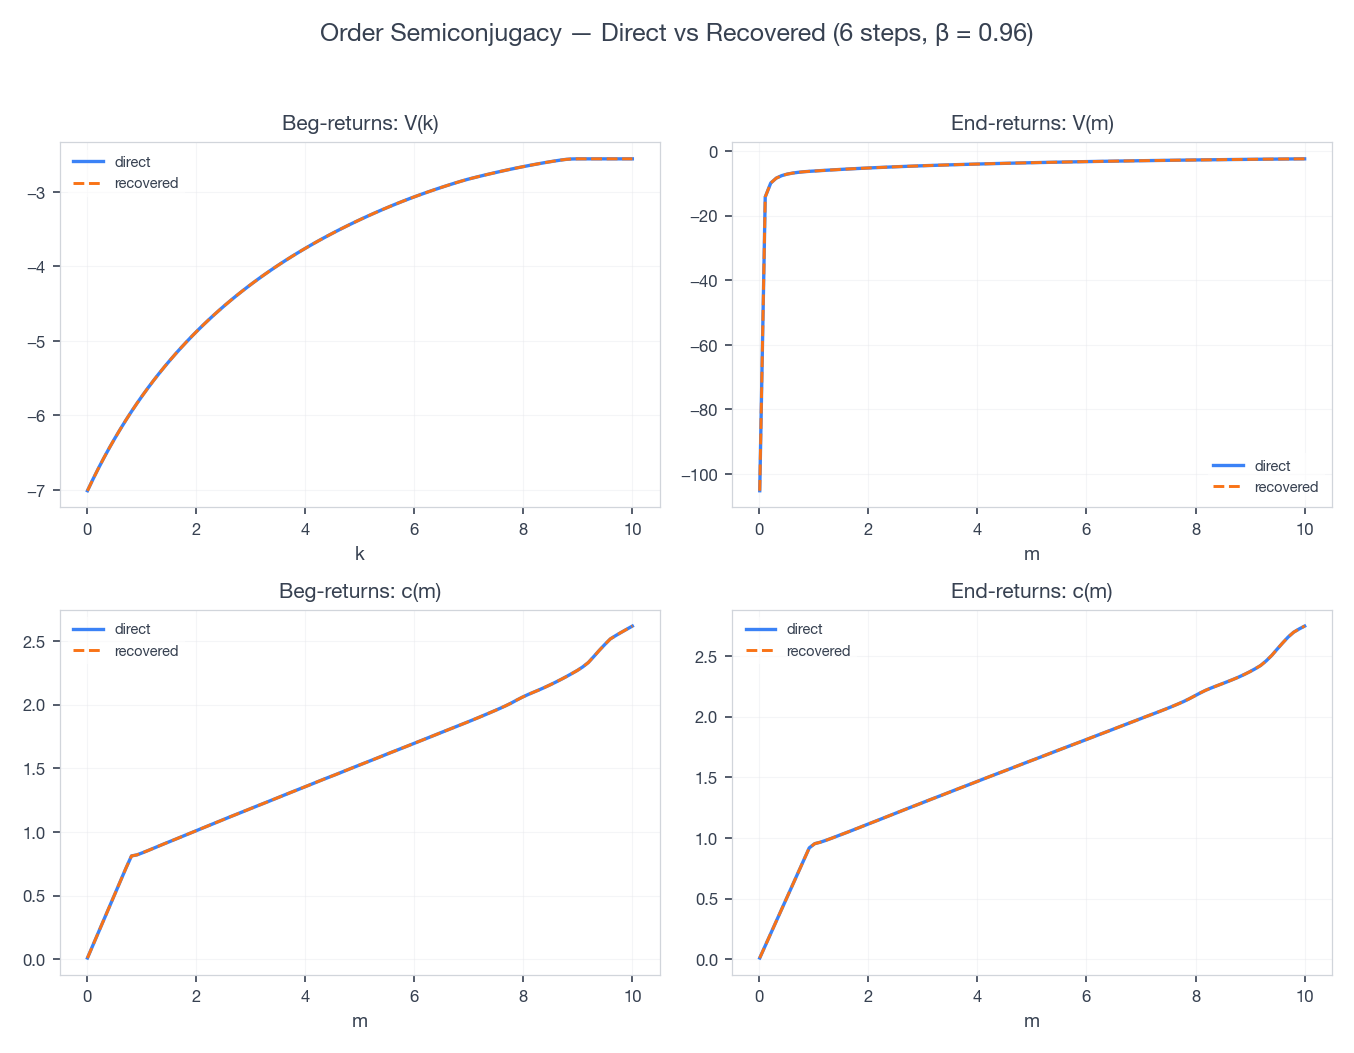
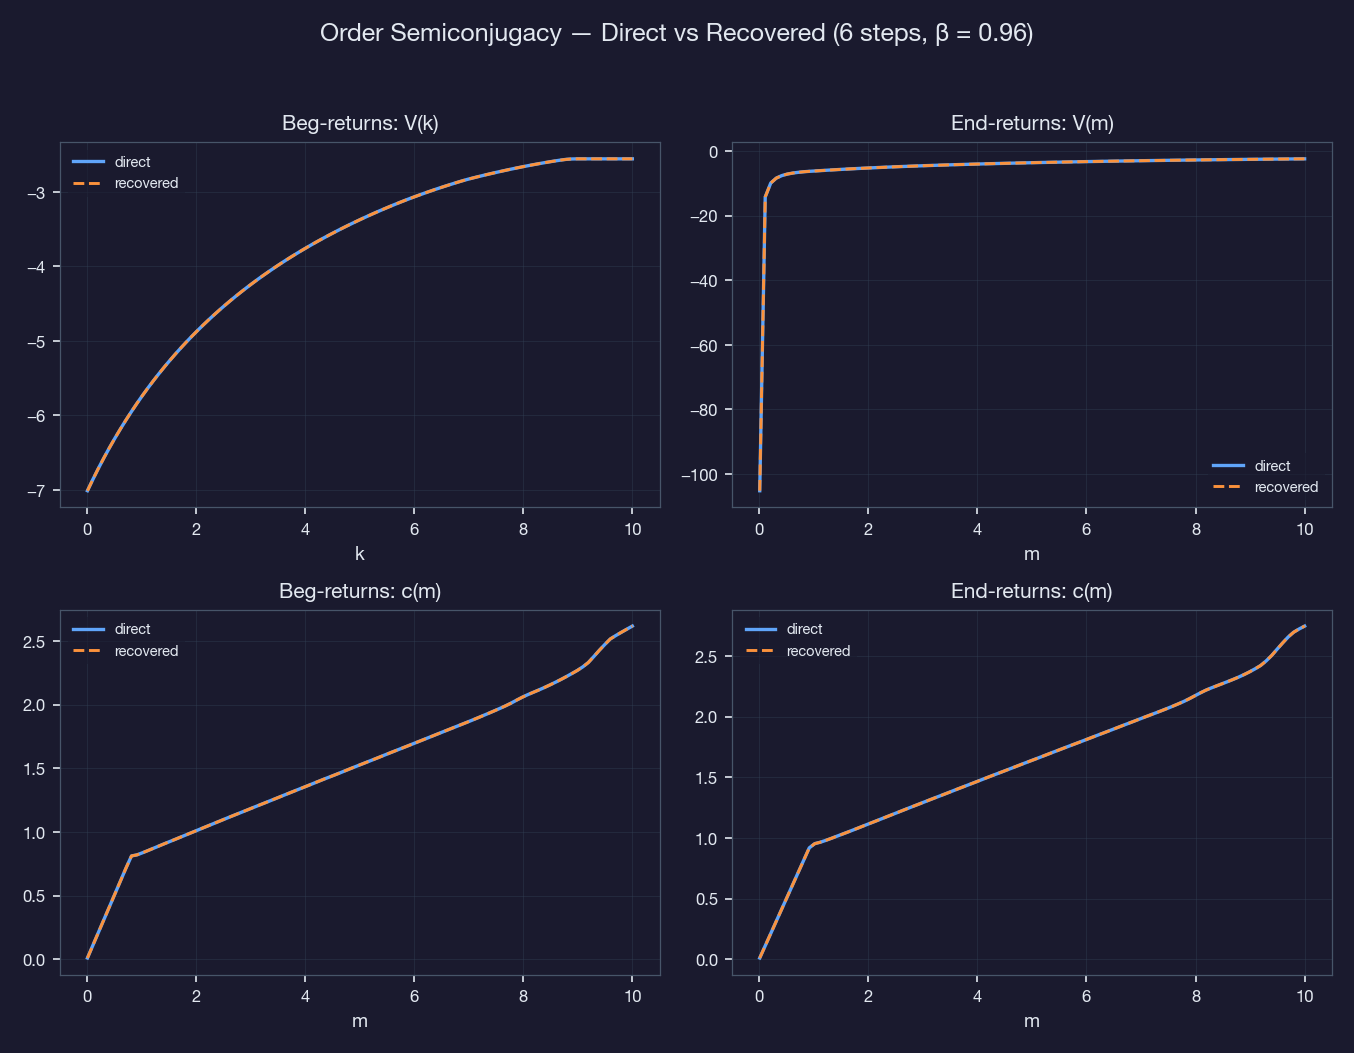

In [21]:
# ── Semiconjugacy comparison plots (dual-theme) ──

from ffp_plots import display_semiconj_plots

display_semiconj_plots(
    V_br, V_beg_recovered, V_m_beg,
    V_er, V_end_recovered,
    n, beta,
)


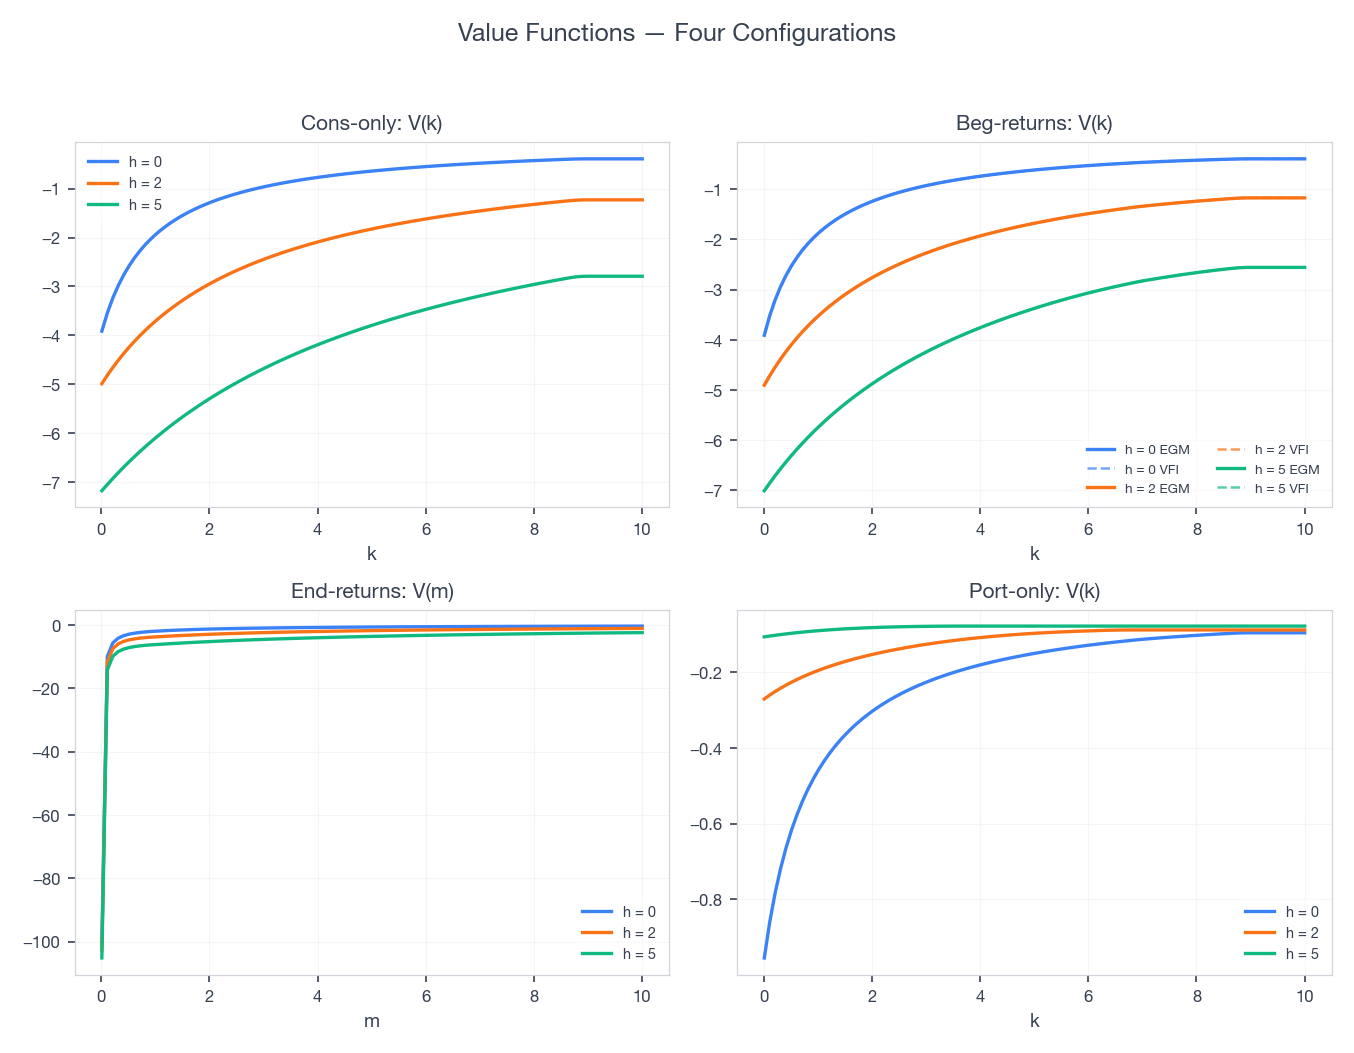
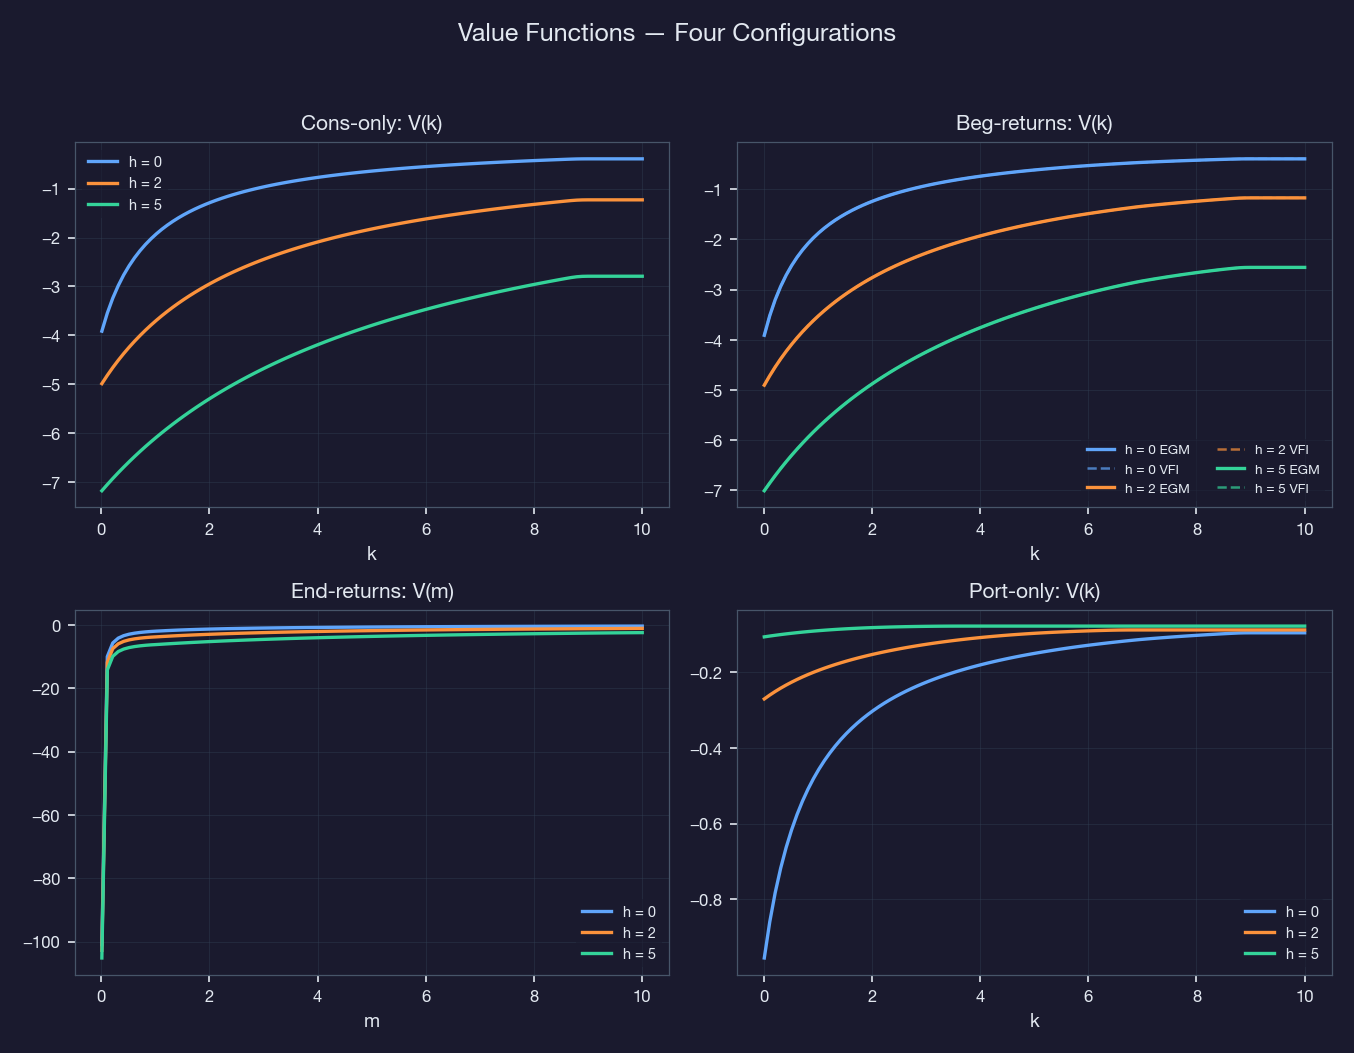


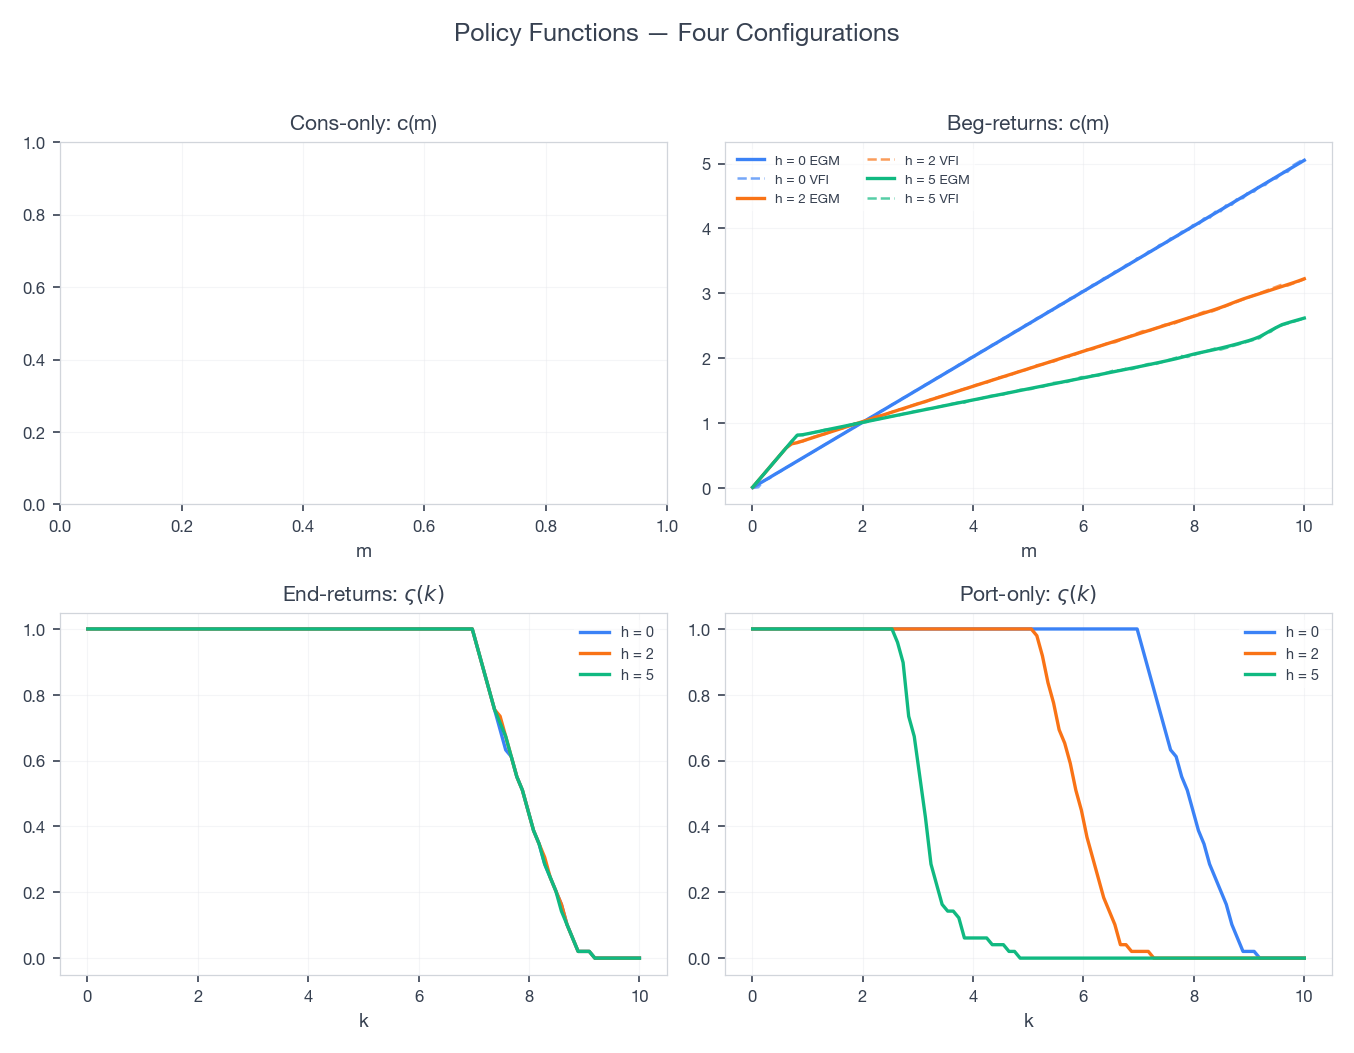
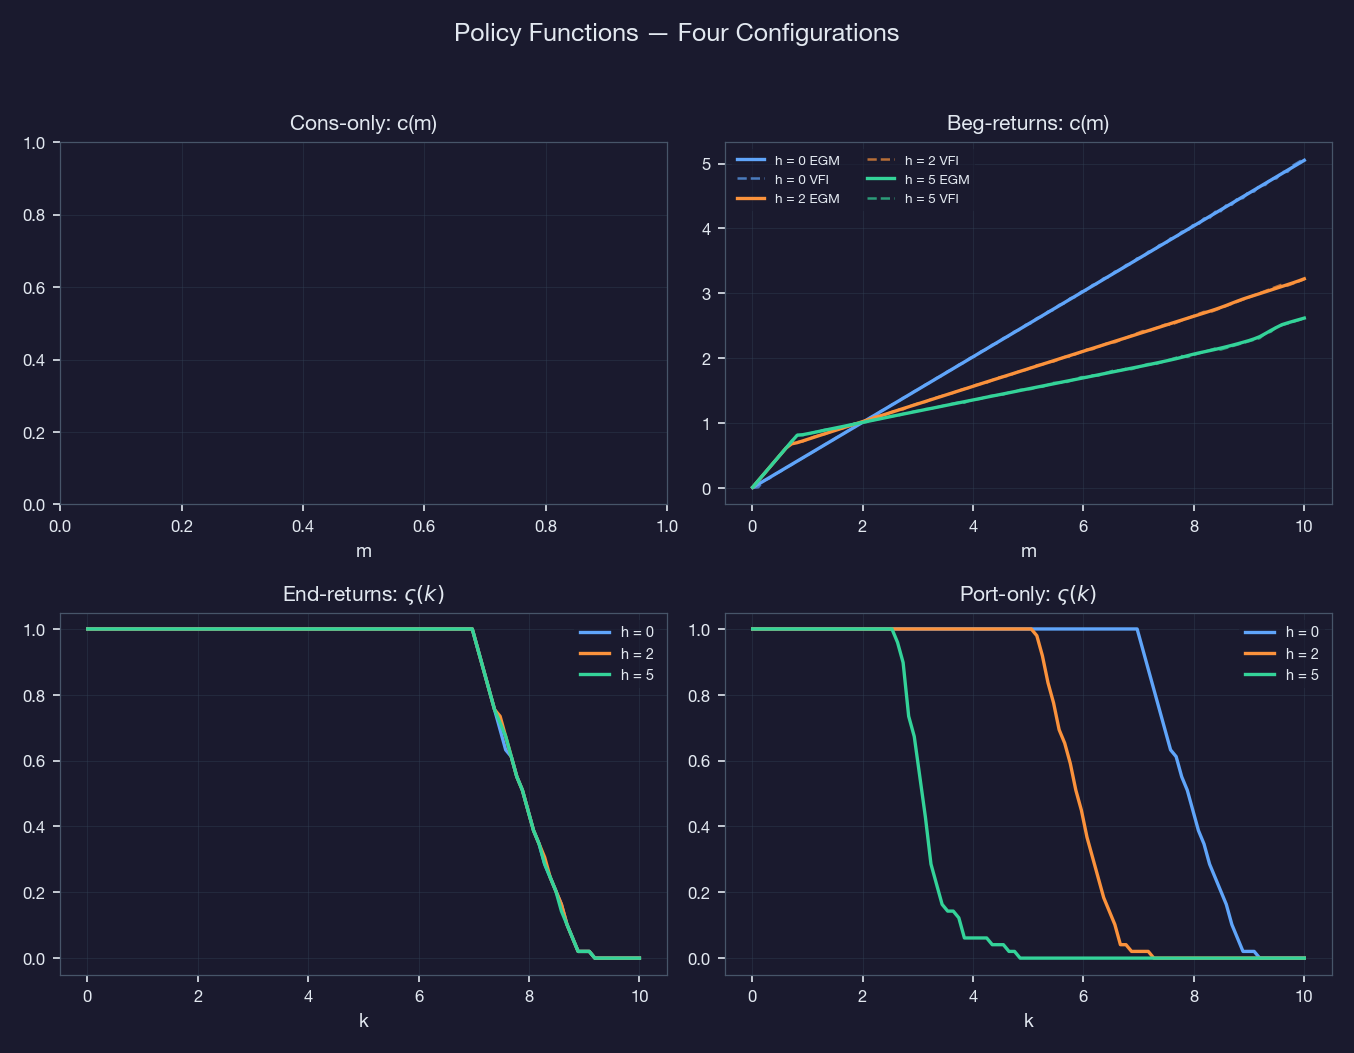

Plots saved (4 PNGs) and displayed with light/dark theme switching.


In [22]:
# ═══════════════════════════════════════════════════════════════
# Plots: all four configurations — dual-theme (light/dark)
# ═══════════════════════════════════════════════════════════════

from ffp_plots import display_dual_plots

display_dual_plots(nest_co, nest_br, nest_bv, nest_er, nest_po, H)

<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## Summary

| Config | Stages | Key feature |
|--------|--------|------------|
| **Cons-only** | noport, cons | Income shocks only |
| **Beg-returns** | port, cons | Returns then consumption |
| **End-returns** | cons, port | Consumption then investment |
| **Port-only** | port | Pure Merton portfolio |

The design principles — modular operators, connector-driven
solve order, equations from the stage syntax — are
exercised throughout.

### References

- Backus, J. (1978). [Can Programming Be Liberated from the
  von Neumann Style? A Functional Style and Its Algebra of
  Programs.](https://dl.acm.org/doi/10.1145/359576.359579)
  *Communications of the ACM*, 21(8), 613–641.
- Carroll, C. D. (2006). *The Method of Endogenous
  Gridpoints for Solving Dynamic Stochastic Optimization
  Problems.* Economics Letters, 91(3).
- Sargent, T. J. & Stachurski, J. (2022).
  [*Economic and Financial Decisions under
  Uncertainty.*](https://johnstachurski.net/efd) Princeton
  University Press.
- Sargent, T. J. & Stachurski, J. (2026).
  *Dynamic Programming: General States.* Cambridge
  University Press.
- Bellman calculus foundations:
  `docs/theory/ddsl-foundations/` and
  `docs/theory/ddsl-foundations/core-ddsl-FFP-concepts.md`

<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## Appendix: seven lives detail

| # | Level | What happens | Object | Source |
|---|-------|-------------|--------|--------|
| 1 | **Symbolic** | YAML parsed into symbols, equations, spaces | `dict` (raw parse tree) | `cons_stage.yaml` |
| 2 | **Parameterized** | Parameter values bound ($\beta$, $\rho$, $R$, ...) | `stage.param` | `calibration.yaml` |
| 3 | **Methodized** | Solution method attached (`!egm`, `!vfi`, ...) | `stage.methods` | `cons_stage_methods.yml` |
| 4 | **Configured** | Numerical settings bound (grid sizes, tolerances) | `stage.settings` | `settings.yaml` |
| 5 | **Callable** | Grids, interpolants, quadrature nodes built | `np.ndarray`, `interp1d` | builder code |
| 6 | **Solved** | Bellman operator iterated to convergence | `ValueFn` (policy + value) | builder code |
| 7 | **Simulated** | Policy applied to generate paths / distributions | `np.ndarray` (paths) | builder code |

Steps 1–4 produce a fully specified stage object (syntax layer).
Step 5 builds callable computational objects (representation).
Steps 6–7 are application (Backus): applying the callables to produce solutions and simulations.

<div style="border-top: 2px solid rgba(0,0,0,0.15); margin: 2.5em 0 1em;"></div>

## Realizing the consumption stage with a HARK handler

We have solved the consumption stage with the in-house EGM and VFI operators. We now solve the *same stage* with a solver from a different toolkit — HARK's `solve_one_period_ConsIndShock` — without changing its economics. The stage YAML, its calibration $(\beta,\rho)$, and its place in the period all stay fixed; only the *realization method* changes.

The wiring is read from the stage's **Rosetta card**, not improvised. The card records HARK's call signature, how Bellman objects map to HARK's arguments (`encode`), how HARK's output maps back (`decode`), and the boundary on which the substitution is exact (`exact_when`). We make three moves:

1. **Change the method** — swap the `policy` node's tag from `!egm` to `!hark`, building a new trellis from the same template.
2. **Honour the contract** — HARK's consumption solver is *model-locked*: it compiles in a buffer-stock budget law. The bare consumption stage carries no return and no income, so we neutralize HARK's transition to the identity $m' = a$ — the card's `exact_when` boundary — and only then does HARK stand in for the stage exactly.
3. **Change a setting** — re-run with a different numerical setting, to show that settings flow through the same interface as cheaply as the method does.

The result is the point of the Rosetta stone: the same stage and the same model, with only the realization changed — and the card tells us exactly how to wire HARK in.

### 1. Change the method

The swap turns a single field: the `method` tag on the stage's `policy` node. `_extract_stage_config` reads that tag and `make_stage_operator` dispatches on it. We deep-copy the EGM methodization loaded in the setup cell and rewrite the `policy` node in place — `!egm → !hark`, with the handler set to the HARK entry. The stage YAML itself does not move.

In [ ]:
import copy

# Turn the one knob: the `policy` node's solution-method tag, EGM -> HARK.
cons_methods_hark = copy.deepcopy(cons_methods)
for _e in cons_methods_hark['methods']:
    if _e.get('on') == 'policy':                                  # the solution-method node
        for _s in _e.get('schemes', []):
            if _s.get('scheme') == 'bellman_backward':            # the policy's backward-solve entry
                _s['method']  = {'__yaml_tag__': 'hark', 'value': ''}   # was egm
                _s['handler'] = 'hark:ConsumptionSaving.solve_one_period_ConsIndShock'
                _s['tool']    = _s['handler']

# Register it next to the EGM and VFI method sets — three one-tag variants of one stage.
stage_methods['cons_stage_hark'] = cons_methods_hark

def build_stage_map_beginning_hark(stages, methods, settings, params):
    '''Beginning-returns with the HARK cons handler (cf. build_stage_map_beginning).'''
    return {
        "cons_stage": bind_stage(stages['cons_stage'], methods['cons_stage_hark'], settings, params),
        "port_stage": bind_stage(stages['port_stage'], methods['port_stage'], settings, params),
    }

def _policy_tag(m):
    for e in m['methods']:
        if e.get('on') == 'policy':
            for s in e.get('schemes', []):
                if s.get('scheme') == 'bellman_backward':
                    t = s.get('method')
                    return t.get('__yaml_tag__') if isinstance(t, dict) else t
    return None

print("Same cons_stage, same YAML — the policy method tag, three ways:")
print(f"  EGM  : !{_policy_tag(cons_methods)}")
print(f"  VFI  : !vfi     (the existing VFI swap)")
print(f"  HARK : !{_policy_tag(cons_methods_hark)}    ->  hark:...solve_one_period_ConsIndShock")
# make_stage_operator only knows egm/vfi; the !hark tag is realized by the operator built below,
# not by the library dispatcher. Binding (methodize/configure/calibrate) is method-agnostic.

### 2. Read the Rosetta card

The interface below is driven by the handler card, not from memory. We load its blocks and display HARK's call signature, the `encode`/`decode` maps, the returns-timing semi-conjugacy, and the `settings_map` that move (3) will use.

In [ ]:
import yaml as _yaml
from IPython.display import HTML, display

_CARD = _repo / 'docs/rosetta-stone/handlers/hark/ConsumptionSaving.solve_one_period_ConsIndShock/blocks'
_handler  = _yaml.safe_load(open(_CARD / 'handler.yaml'))['handler']
_contract = _yaml.safe_load(open(_CARD / 'adapter_contract.yaml'))['adapter_contract']
_meta     = _yaml.safe_load(open(_CARD / 'meta.yaml'))

_rt  = _contract['s_transformations'][0]          # the returns_timing slider
_sig = ' '.join(_handler['signature'].split())
_enc = ''.join(f"<li>{e}</li>" for e in _contract['encode'])
_dec = ''.join(f"<li>{e}</li>" for e in _contract['decode'])
_sm  = ''.join(f"<tr><td><code>{k}</code></td><td>&rarr;</td><td><code>{v}</code></td></tr>"
               for k, v in _meta['settings_map'].items())

display(HTML(f'''
<div style="font-family:-apple-system,Segoe UI,Roboto,sans-serif; max-width:860px;
            border:1px solid #d8dee9; border-radius:10px; overflow:hidden;
            box-shadow:0 1px 3px rgba(20,33,61,.08); margin:.5em 0;">
  <div style="background:#14213d; color:#fff; padding:14px 18px;">
    <div style="font-size:.72rem; letter-spacing:.12em; text-transform:uppercase; color:#9fb3c8;">
      Rosetta handler card &middot; toolkit.hark</div>
    <div style="font-size:1.05rem; font-weight:600; margin-top:2px;">
      ConsumptionSaving.solve_one_period_ConsIndShock</div>
  </div>
  <div style="padding:16px 18px; color:#14213d;">
    <div style="font-size:.78rem; color:#5b6b7d; margin-bottom:4px;">CALL SIGNATURE</div>
    <code style="display:block; background:#f4f6fa; border-radius:6px; padding:8px 10px;
                 font-size:.82rem; white-space:pre-wrap;">{_sig}</code>
    <div style="display:flex; gap:24px; flex-wrap:wrap; margin-top:16px;">
      <div style="flex:1; min-width:240px;">
        <div style="font-size:.78rem; color:#2a9d8f; font-weight:600;">ENCODE &nbsp;Bellman &rarr; HARK</div>
        <ul style="margin:6px 0; padding-left:18px; font-size:.84rem;">{_enc}</ul>
      </div>
      <div style="flex:1; min-width:240px;">
        <div style="font-size:.78rem; color:#e76f51; font-weight:600;">DECODE &nbsp;HARK &rarr; Bellman</div>
        <ul style="margin:6px 0; padding-left:18px; font-size:.84rem;">{_dec}</ul>
      </div>
    </div>
    <div style="margin-top:14px; padding:12px 14px; background:#f4f6fa; border-radius:8px;">
      <div style="font-size:.78rem; color:#5b6b7d; font-weight:600;">RETURNS-TIMING SLIDER (semi-conjugacy)</div>
      <div style="font-size:.84rem; margin-top:6px;">
        <b>M</b> (consumption max): <code>{_rt["M"]}</code><br>
        <b>E</b> (income expectation): <code>{_rt["E"]}</code><br>
        primary <code>S = E&#8728;M</code> &nbsp;&middot;&nbsp; subordinate <code>S&#770; = M&#8728;E</code> (HARK's form)
      </div>
      <div style="font-size:.8rem; color:#5b6b7d; margin-top:8px;">
        <b>exact_when:</b> {_rt["exact_when"].split(".")[0]}.</div>
    </div>
    <div style="margin-top:14px;">
      <div style="font-size:.78rem; color:#5b6b7d; font-weight:600;">SETTINGS MAP (move 3)</div>
      <table style="font-size:.84rem; margin-top:4px; border-collapse:collapse;">{_sm}</table>
    </div>
  </div>
</div>'''))
print("model_locked (may_not_touch):", ', '.join(_meta['may_not_touch']))

### 3. Build the HARK interface from the contract

We build the consumption operator $\mathbb{M}_{\text{cons}}^{\text{HARK}}$ directly from the card. *Encode*: the bare stage's $\beta,\rho$ and the incoming continuation value become HARK's call arguments, and we **neutralize the model-locked budget law** — $R_{\text{free}}=1$, $\Gamma=1$, and a degenerate income draw $\{\psi=1,\,\theta=0\}$ — so that HARK's $m' = a$ coincides with the stage's continuation over post-decision assets. *Invoke*: one backward step ($n=1$ is native, no convergence wrapper). *Decode*: HARK's `cFunc` is the consumption policy, and the stage value follows from its own Bellman equation $V(m) = u(c) + V_{\text{cont}}(m-c)$.

Recall that $\beta$ is applied to the continuation by `S_disc` before the stage operator sees it, so the HARK call sets `DiscFac = 1`. Below HARK's borrowing constraint the consumption function is undefined; there the agent consumes available resources, $c \approx m$, exactly as the endogenous-grid solution does at its lower boundary.

In [ ]:
from HARK.ConsumptionSaving.ConsIndShockModel import solve_one_period_ConsIndShock, ConsumerSolution
from HARK.interpolation import LinearInterp, MargValueFuncCRRA, ValueFuncCRRA
from HARK.distributions import DiscreteDistributionLabeled

def _continuation_as_HARK(V_cont, crra):
    '''encode: wrap an already-discounted ValueFn over assets a as HARK's solution_next.
    vPfunc reproduces dV via the CRRA pseudo-cFunc g=dV^(-1/rho) (since u'(g)=g^(-rho)=dV);
    vFunc reproduces V via inverse utility. Boundary sentinels are clipped to stay finite.'''
    g  = np.asarray(V_cont.grid, float)
    dv = np.clip(np.asarray(V_cont.dV(g), float), 1e-12, 1e10)
    vv = np.clip(np.asarray(V_cont.values, float), -1e10, -1e-12)
    pseudo_c = dv ** (-1.0 / crra)
    vnvrs    = ((1 - crra) * vv) ** (1.0 / (1 - crra))
    return ConsumerSolution(
        cFunc=LinearInterp(g, pseudo_c), vPfunc=MargValueFuncCRRA(LinearInterp(g, pseudo_c), crra),
        vFunc=ValueFuncCRRA(LinearInterp(g, vnvrs), crra),
        mNrmMin=0.0, hNrm=0.0, MPCmin=1.0, MPCmax=1.0)

def make_hark_cons_operator(stage, n_a=None, cubic=False, announce=True):
    '''A cons-stage operator realized by HARK's ConsIndShock solver, neutralized to m'=a.
    Same shape as make_stage_operator's output: S(V_cont: ValueFn) -> ValueFn, with ._method.'''
    crra  = float(stage.calibration['ρ'])
    n_a   = int(stage.settings.get('n_a', 100)) if n_a is None else n_a
    a_max = float(stage.settings.get('a_max', 10.0))
    aXtraGrid  = np.linspace(1e-6, a_max, n_a)                       # a_grid_egm  (settings_map)
    IncShkDstn = DiscreteDistributionLabeled(                        # degenerate income: m' = a
        pmv=np.array([1.0]), atoms=np.array([[1.0], [0.0]]), var_names=['PermShk', 'TranShk'])
    if announce:
        print(f"    {stage.name} (hark): ConsIndShock, neutralized m'=a, "
              f"n_a={n_a}, {'cubic' if cubic else 'linear'}")

    def S_cons_hark(V_cont):
        sol = solve_one_period_ConsIndShock(
            solution_next=_continuation_as_HARK(V_cont, crra), IncShkDstn=IncShkDstn,
            LivPrb=1.0, DiscFac=1.0, CRRA=crra, Rfree=1.0, PermGroFac=1.0,   # neutralized
            BoroCnstArt=0.0, aXtraGrid=aXtraGrid, vFuncBool=False, CubicBool=cubic)
        c_raw = sol.cFunc(m_grid)                                    # HARK's consumption policy
        c = np.clip(np.where(np.isfinite(c_raw), c_raw, m_grid), 1e-10, m_grid - 1e-10)
        a = m_grid - c
        V  = np.where(c > 0, c**(1 - crra) / (1 - crra), -1e10) + V_cont(a)   # stage Bellman value
        dV = np.where(c > 0, c**(-crra), 1e10)                                # envelope condition
        return ValueFn(m_grid, V, dV, {'c': c, 'a': a})

    S_cons_hark._method = 'hark'
    S_cons_hark._stage  = stage.name
    return S_cons_hark

print("HARK consumption operator ready (built from the card's encode / neutralize / decode).")

### 4. Solve the lifecycle with HARK, and check it against EGM

We run the beginning-returns lifecycle with the HARK consumption operator in place of EGM, holding the portfolio stage and everything else fixed — $S = \mathbb{E}_{\text{port}} \circ \mathbb{M}_{\text{cons}}^{\text{HARK}} \circ D$, the same period composition as the EGM solve above. Since the consumption stage is deterministic, the two realizations should agree up to interpolation.

In [ ]:
# Beginning-returns lifecycle, with M_cons realized by HARK.  S = E_port o M_cons^HARK o D.
V_bk = make_terminal(a_grid)
nest_bk = {"solutions": []}
print(f"Beginning-returns with HARK cons (H={H}):\n")
for h in range(H + 1):
    bc = bind_stage(stage_models['cons_stage'], stage_methods['cons_stage_hark'], settings, dict(base_params))
    bp = bind_stage(stage_models['port_stage'], stage_methods['port_stage'],      settings, dict(base_params))
    S_cons_hark = make_hark_cons_operator(bc, announce=(h == 0))     # M_cons^HARK
    S_port      = make_stage_operator(bp)                            # E_port (unchanged)

    if h > 0:
        V_bk = nest_bk["solutions"][-1]["k"]

    V_bk = S_disc(V_bk)                                              # D : discount the continuation
    V_cons = S_cons_hark(V_bk)                                       # M_cons^HARK
    V_bk = S_port(V_cons)                                            # E_port
    V_bk.policy['_cons_stage'] = V_cons

    nest_bk["solutions"].append({"k": V_bk, "m": V_cons})
    print(f"  h={h}: V_port ∈ [{V_bk.values.min():.4f}, {V_bk.values.max():.4f}]  (cons: !hark, port: !vfi)")

# Compare against the EGM beginning-returns solve (V_br, from the EGM cell above).
c_egm  = V_br.policy['_cons_stage'].policy['c']
c_hark = nest_bk["solutions"][-1]["m"].policy['c']
interior = m_grid > 1.0
dpol = np.max(np.abs(c_egm[interior]  - c_hark[interior]))
dval = np.max(np.abs(V_br.values[interior] - V_bk.values[interior]))
print(f"\nSame stage, two realizations (interior, m>1):")
print(f"  max |c_EGM(m) − c_HARK(m)| = {dpol:.2e}")
print(f"  max |V_EGM(k) − V_HARK(k)| = {dval:.2e}")
print("HARK reproduces the deterministic consumption stage to interpolation tolerance.")

In [ ]:
# Consumption policy: EGM vs the HARK realization (they coincide).
import matplotlib.pyplot as plt

NAVY, ORANGE, TEAL = '#14213d', '#e76f51', '#2a9d8f'
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

ax[0].plot(m_grid, c_egm,  color=NAVY,   lw=2.4, label='EGM (in-house)')
ax[0].plot(m_grid, c_hark, color=ORANGE, lw=1.6, ls='--', label='HARK ConsIndShock')
ax[0].set_xlabel('market resources $m$'); ax[0].set_ylabel('consumption $c(m)$')
ax[0].set_title('Consumption policy — same stage, two solvers'); ax[0].legend(frameon=False)

ax[1].semilogy(m_grid[interior], np.abs(c_egm - c_hark)[interior] + 1e-16, color=TEAL, lw=1.8)
ax[1].set_xlabel('market resources $m$'); ax[1].set_ylabel('$|c_{EGM}-c_{HARK}|$')
ax[1].set_title('Difference (interior)')
for a in ax:
    a.spines[['top', 'right']].set_visible(False); a.grid(alpha=.25)
fig.tight_layout(); plt.show()

### 5. Change a setting

The numerical settings flow through the same interface as the method. We re-run the HARK solve with a coarser and a finer end-of-period asset grid — `a_grid_egm → aXtraGrid` in the card's `settings_map` — and confirm the consumption policy tracks the refinement, with no change to the economics.

In [ ]:
# Move the Rho-level knob: aXtraGrid size, via the card's settings_map (a_grid_egm -> aXtraGrid).
def solve_beginning_hark(n_a, cubic=False):
    V = make_terminal(a_grid); sols = []
    for h in range(H + 1):
        bc = bind_stage(stage_models['cons_stage'], stage_methods['cons_stage_hark'], settings, dict(base_params))
        bp = bind_stage(stage_models['port_stage'], stage_methods['port_stage'],      settings, dict(base_params))
        Sc = make_hark_cons_operator(bc, n_a=n_a, cubic=cubic, announce=False)
        Sp = make_stage_operator(bp)
        if h > 0:
            V = sols[-1]["k"]
        Vc = Sc(S_disc(V)); V = Sp(Vc); V.policy['_cons_stage'] = Vc
        sols.append({"k": V, "m": Vc})
    return sols[-1]["m"].policy['c']

settings_grid = [25, 50, 100, 400]
c_by_setting = {n: solve_beginning_hark(n) for n in settings_grid}

j = int(0.5 * len(m_grid))
print("aXtraGrid size  ->  c(m≈%.1f)   (finer grid, more accurate)" % m_grid[j])
for n in settings_grid:
    print(f"   n_a = {n:>3}        {c_by_setting[n][j]:.5f}")

fig, ax = plt.subplots(figsize=(6.4, 4.0))
shades = ['#9fb3c8', '#5b80a8', '#2f5d8a', '#14213d']
for n, col in zip(settings_grid, shades):
    ax.plot(m_grid, c_by_setting[n], color=col, lw=2.0, label=f'aXtraGrid n={n}')
ax.set_xlabel('market resources $m$'); ax.set_ylabel('consumption $c(m)$')
ax.set_title('Same handler, one setting changed (asset-grid size)')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False); ax.grid(alpha=.25)
fig.tight_layout(); plt.show()